# **K-NN Histogram Classification via Semantic Clustering**

In this notebook, we transition from analyzing Out-of-Distribution (OOD) subjects to building a quantifiable classification pipeline. Building upon our previous experiments segmenting and clustering semantic features, we will now attempt to classify images based entirely on their feature distributions (Bag of Visual Words histograms).

To establish a mathematical baseline and validate our architecture, we will begin our experiments on a fundamental computer vision dataset: the **MNIST handwritten digits**.

Our methodology involves:
1. Extracting deep spatial features and grouping them into semantic clusters.
2. Constructing frequency histograms that represent the distinct "semantic fingerprint" of each image.
3. Utilizing a **K-Nearest Neighbors (K-NN)** classifier—equipped with a **Chi-Square distance metric**—to classify the digits based on their histogram similarities.

Furthermore, we will rigorously experiment with the vocabulary size (the number of K-Means clusters, $K$). We will test a spectrum of spatial resolutions, ranging from low-dimensional conceptual spaces ($K=4$) to highly fractured, micro-textural spaces ($K \ge 1000$).

Successfully validating this pipeline on MNIST will serve as the foundational proof-of-concept required to transition into complex **Hierarchical Classification** in the near future.

## **0. Model Preparation**

### **Imports**

In [2]:
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import kagglehub
from transformers import AutoImageProcessor, AutoModel

### **Model Preparation**

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [22]:
#model_name = "facebook/dinov3-vit7b16-pretrain-lvd1689m" # Flagship
model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vits16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 12 layers.


## **1. Dataset Prep**

### **1.1 Imports**

In [23]:
from torchvision import transforms
import matplotlib.pyplot as plt

### **1.2 Downloading the MNIST Numbers**

In [24]:
#Define a basic transform (Convert to PIL Image so it matches our DINOv3 pipeline)
# DINO expects RGB images, but MNIST is grayscale (1 channel).
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # Convert 1-channel to 3-channel RGB
    transforms.Resize((224, 224)),               # Resize to a standard DINOv3 resolution
])

In [25]:
mnist_train_full = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test_full = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

### **1.3 Function definition to sample dataset**

In [26]:
def get_balanced_subset(dataset, num_per_class=10):
    class_counts = {i: 0 for i in range(10)}
    subset_images = []
    subset_labels = []

    for img, label in dataset:
        if class_counts[label] < num_per_class:
            subset_images.append(img)
            subset_labels.append(label)
            class_counts[label] += 1

        if all(count == num_per_class for count in class_counts.values()):
            break

    return subset_images, subset_labels

In [106]:
train_images, train_labels = get_balanced_subset(mnist_train_full, num_per_class=100)
test_images, test_labels = get_balanced_subset(mnist_test_full, num_per_class=50)

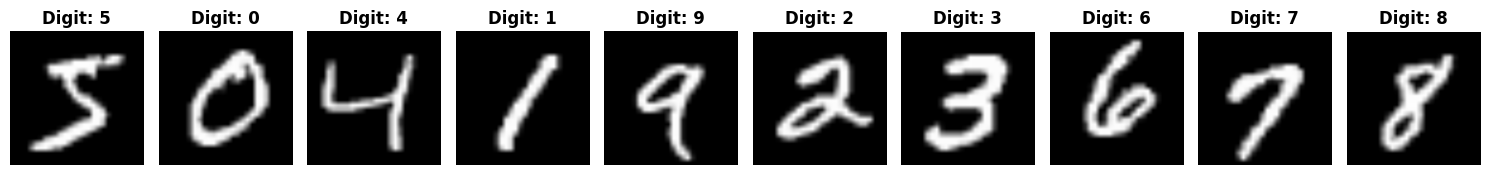

In [107]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
plotted_digits = set()
plot_idx = 0

for img, label in zip(train_images, train_labels):
    if label not in plotted_digits:
        axes[plot_idx].imshow(img)
        axes[plot_idx].set_title(f"Digit: {label}", fontweight='bold')
        axes[plot_idx].axis('off')
        plotted_digits.add(label)
        plot_idx += 1
    if len(plotted_digits) == 10:
        break

plt.tight_layout()
plt.show()

## **2. Feature Extraction and Clustering**

### **2.1 Passing it through the model**

In [108]:
patch_size = 16
train_features_list = [] # Stores features per image (we need this to build histograms later)
all_train_patches = []   # Stores ALL patches stacked (we need this to train K-Means)


In [109]:
model.eval()
with torch.no_grad():
    for i, img in enumerate(train_images):

        # Calculate the dynamic grid (though we know it will be 14x14 for 224x224 images)
        w, h = img.size
        grid_w = w // patch_size
        grid_h = h // patch_size
        num_spatial_patches = grid_w * grid_h

        inputs = processor(images=img, return_tensors="pt").to(device)

        outputs = model(**inputs)

        patch_tokens = outputs.last_hidden_state[0, -num_spatial_patches:, :].cpu().numpy()

        train_features_list.append(patch_tokens)
        all_train_patches.append(patch_tokens)

        # Print progress
        if (i + 1) % 20 == 0:
            print(f"✅ Processed {i + 1}/{len(train_images)} images...")

✅ Processed 20/1000 images...
✅ Processed 40/1000 images...
✅ Processed 60/1000 images...
✅ Processed 80/1000 images...
✅ Processed 100/1000 images...
✅ Processed 120/1000 images...
✅ Processed 140/1000 images...
✅ Processed 160/1000 images...
✅ Processed 180/1000 images...
✅ Processed 200/1000 images...
✅ Processed 220/1000 images...
✅ Processed 240/1000 images...
✅ Processed 260/1000 images...
✅ Processed 280/1000 images...
✅ Processed 300/1000 images...
✅ Processed 320/1000 images...
✅ Processed 340/1000 images...
✅ Processed 360/1000 images...
✅ Processed 380/1000 images...
✅ Processed 400/1000 images...
✅ Processed 420/1000 images...
✅ Processed 440/1000 images...
✅ Processed 460/1000 images...
✅ Processed 480/1000 images...
✅ Processed 500/1000 images...
✅ Processed 520/1000 images...
✅ Processed 540/1000 images...
✅ Processed 560/1000 images...
✅ Processed 580/1000 images...
✅ Processed 600/1000 images...
✅ Processed 620/1000 images...
✅ Processed 640/1000 images...
✅ Processed 

In [110]:
# Stack all patches into one massive 2D array for K-Means training
X_train_massive = np.vstack(all_train_patches)

### **2.2 Clustering**
We will be clustering for numerous value.
For our experiment we will be conducting with multiples of 4. Meaning we will try 4, 16, 64, 256

In [111]:
from sklearn.cluster import KMeans

In [112]:
k_values = [4, 16, 64, 256]

kmeans_models = {}
train_cluster_labels_dict = {}

**Note:** Why did DINOv3 output NaNs?

MNIST images have a lot of purely black background. This means many of your 16×16 patches are perfectly uniform, with absolutely zero variance in pixel intensity.

When DINOv3's internal Layer Normalization tries to process those pure black patches, it mathematically divides by the variance. Dividing by zero (or an incredibly small number when using float16 precision on a GPU) causes the math to explode, resulting in a NaN.
The Fix (No need to re-extract!)

Since we know these NaNs represent exactly one thing—the empty black background—we can safely replace them with 0.0 before passing them to K-Means. This mathematically anchors the "empty space" cluster!

In [113]:
nan_count = np.isnan(X_train_massive).sum()
print(f"Cleaning Data: Found {nan_count} NaN values. Converting them to 0.0...")

Cleaning Data: Found 0 NaN values. Converting them to 0.0...


In [114]:
X_train_massive_clean = np.nan_to_num(X_train_massive, nan=0.0, posinf=0.0, neginf=0.0)

**Note:** We had to use `torch_dtype=torch.float32`
Why did this happen?

When we used `np.nan_to_num` to turn the NaNs into zeros, it turns out that almost all of your patches were NaNs. So, K-Means was literally just looking at an array of 19,600 identical zeros.
The Root Cause: The float16 Curse

This is a famous bug when using Vision Transformers on MNIST. In our model-loading code, we used torch.float16 to save memory. But MNIST backgrounds are perfectly black (absolute zero). When DINOv3's Layer Normalization tries to do math on absolute zeros using float16 precision, the numbers underflow, it divides by zero, and the entire neural network outputs pure NaNs!

In [115]:
print(f"Starting K-Means clustering on {X_train_massive_clean.shape[0]} patches...")

for k in k_values:
    print(f"🧩 Training Visual Vocabulary with K = {k}...")

    n_init_val = 10 if k <= 64 else 1

    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=n_init_val)

    # Notice we are passing the CLEANED array now!
    labels = kmeans.fit_predict(X_train_massive_clean)

    kmeans_models[k] = kmeans
    train_cluster_labels_dict[k] = labels

print("\n✅ All clustering models trained and saved perfectly!")

Starting K-Means clustering on 196000 patches...
🧩 Training Visual Vocabulary with K = 4...
🧩 Training Visual Vocabulary with K = 16...
🧩 Training Visual Vocabulary with K = 64...
🧩 Training Visual Vocabulary with K = 256...

✅ All clustering models trained and saved perfectly!


### **2.3 Plotting**

In [91]:
def plot_mnist_clusters(k, train_images, train_labels, train_cluster_labels_dict):
    """
    Plots a 2x10 grid showing 2 examples of each MNIST digit overlaid
    with their K-Means semantic cluster assignments.
    """
    # 1. Grab 2 indices for each digit (0-9)
    indices_by_digit = {d: [] for d in range(10)}
    for idx, label in enumerate(train_labels):
        if len(indices_by_digit[label]) < 2:
            indices_by_digit[label].append(idx)

    # 2. Assign the colormap based on the vocabulary size
    if k <= 10:
        cmap_name = 'tab10'
    elif k <= 20:
        cmap_name = 'tab20'
    else:
        cmap_name = 'turbo'
    discrete_cmap = plt.get_cmap(cmap_name, k)

    # 3. Create the 2x10 grid
    fig, axes = plt.subplots(2, 10, figsize=(20, 5))
    fig.suptitle(f"Micro-Semantic Grouping: K = {k}", fontsize=20, fontweight='bold', y=1.05)

    for digit in range(10):
        for row in range(2):
            global_idx = indices_by_digit[digit][row]
            img = train_images[global_idx]

            # Slice the exact 196 labels for this specific image
            start_idx = global_idx * 196
            end_idx = start_idx + 196
            img_labels_1d = train_cluster_labels_dict[k][start_idx:end_idx]

            # Reshape back into the 14x14 grid
            cluster_grid_2d = img_labels_1d.reshape((14, 14))

            # Plot the original image and the cluster overlay
            axes[row, digit].imshow(img)
            axes[row, digit].imshow(
                cluster_grid_2d,
                cmap=discrete_cmap,
                alpha=0.6,
                extent=[0, 224, 224, 0],
                interpolation='nearest',
                vmin=-0.5,
                vmax=k - 0.5
            )
            axes[row, digit].axis('off')

            if row == 0:
                axes[row, digit].set_title(f"Digit {digit}", fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

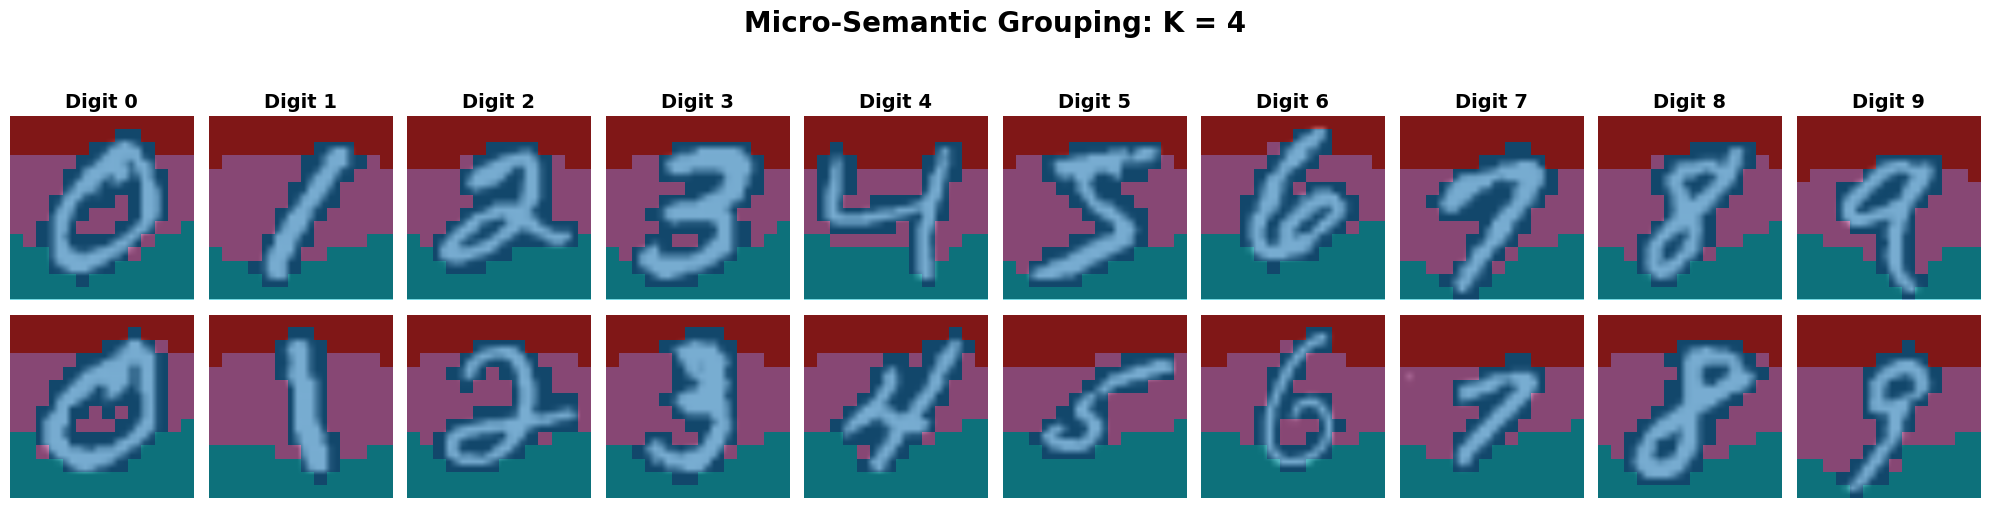

In [40]:
plot_mnist_clusters(4, train_images, train_labels, train_cluster_labels_dict)

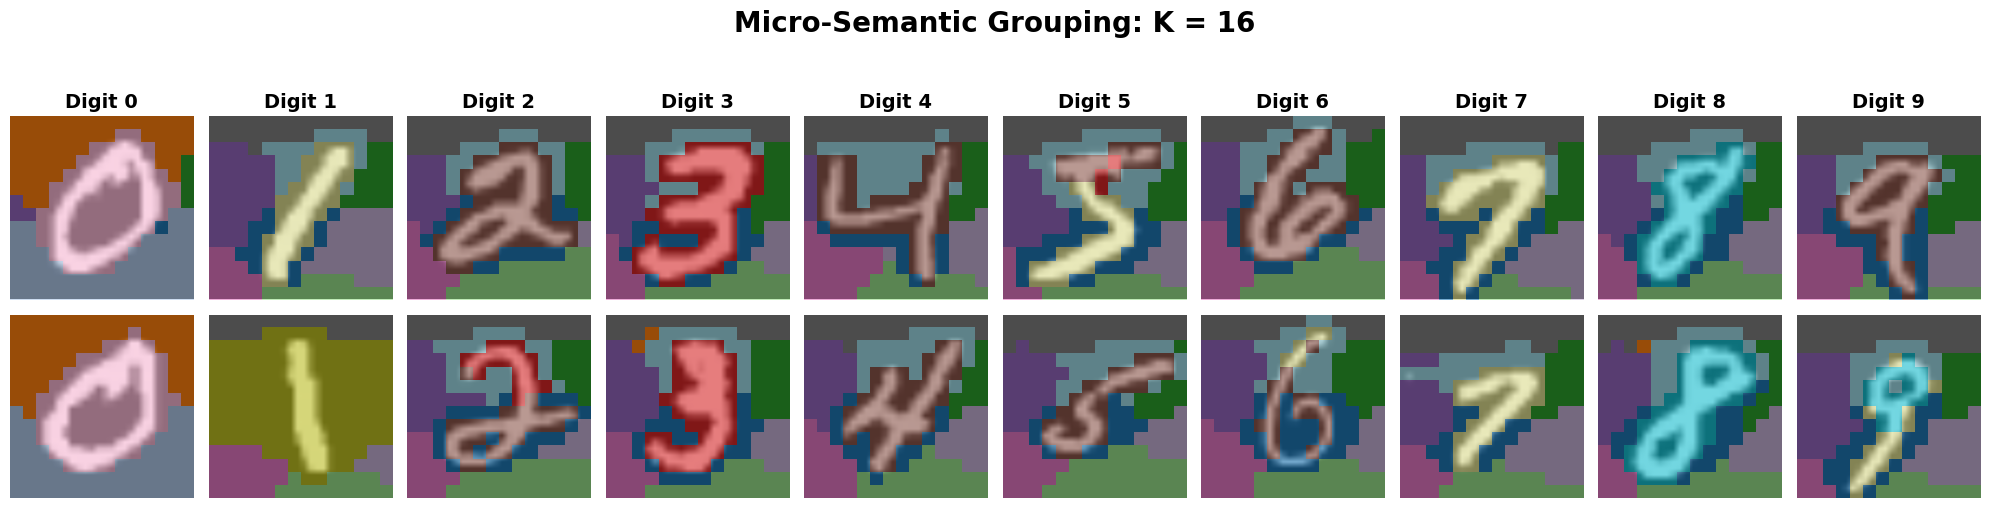

In [42]:
plot_mnist_clusters(16, train_images, train_labels, train_cluster_labels_dict)

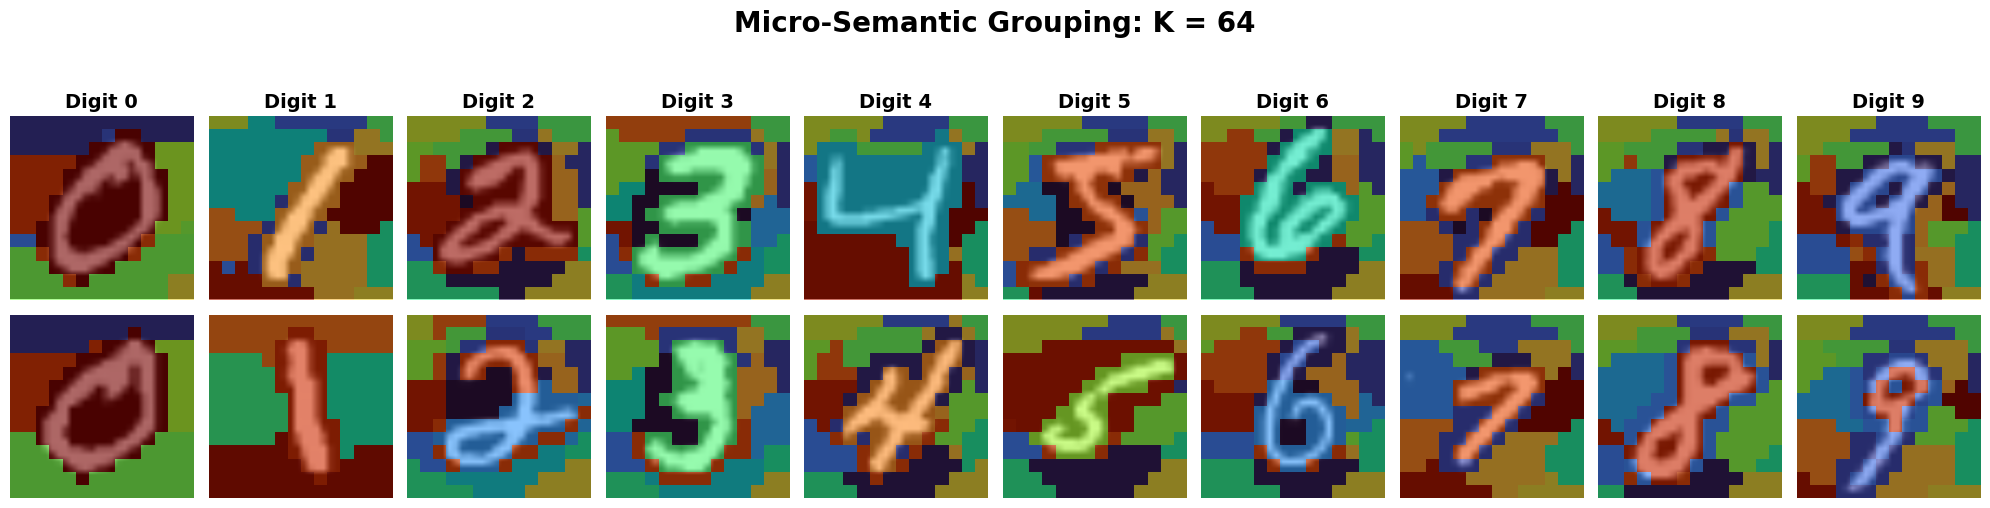

In [43]:
plot_mnist_clusters(64, train_images, train_labels, train_cluster_labels_dict)

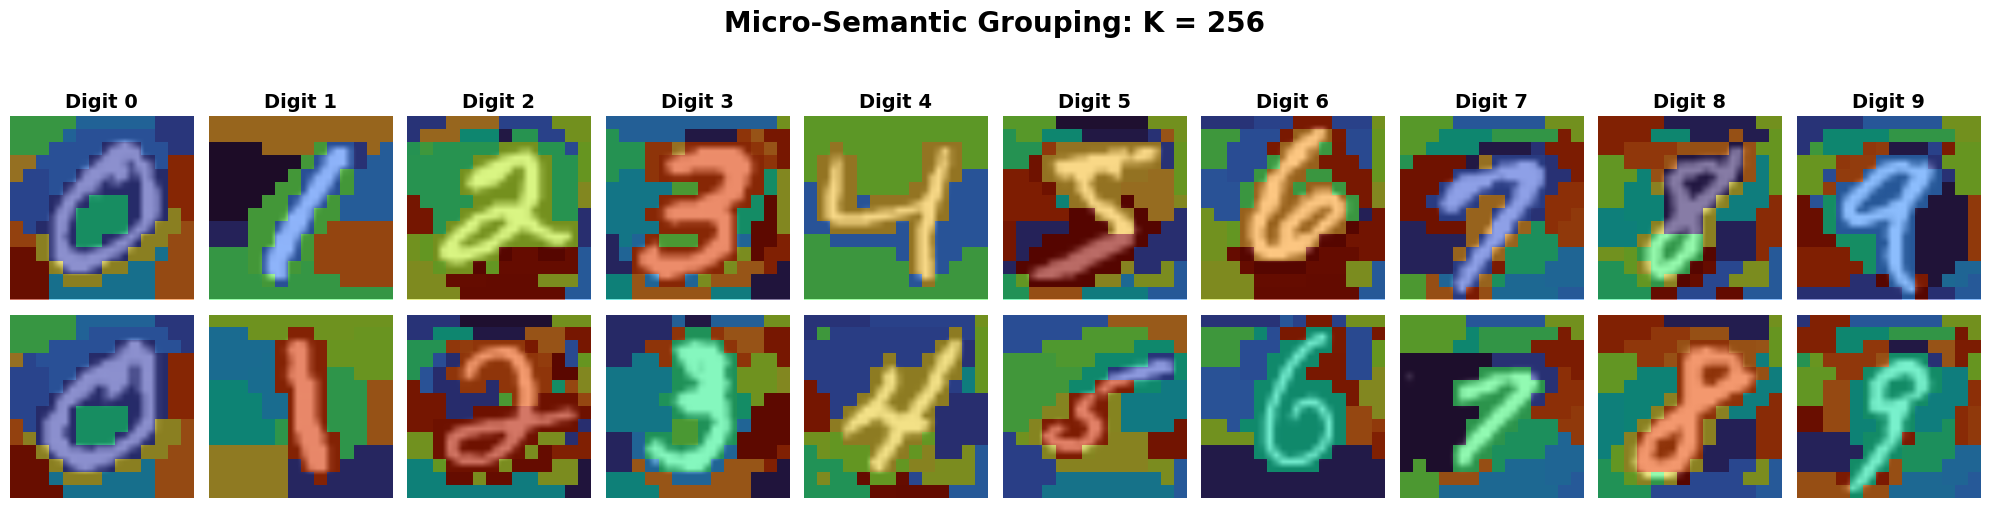

In [41]:
plot_mnist_clusters(256, train_images, train_labels, train_cluster_labels_dict)

### **2.4 Histograms**

In [92]:
def plot_average_histograms(k, train_labels, train_cluster_labels_dict, patches_per_img=196):
    """
    Calculates and plots the average Bag of Visual Words (BoVW) histogram
    for each digit (0-9) at a specific vocabulary size K.
    """
    indices_by_digit = {d: [] for d in range(10)}
    for idx, label in enumerate(train_labels):
        indices_by_digit[label].append(idx)

    # Calculate average histograms
    avg_histograms = np.zeros((10, k))

    for digit, indices in indices_by_digit.items():
        digit_hists = []
        for idx in indices:
            start_idx = idx * patches_per_img
            end_idx = start_idx + patches_per_img
            img_labels = train_cluster_labels_dict[k][start_idx:end_idx]

            counts = np.bincount(img_labels, minlength=k)
            frequencies = counts / patches_per_img
            digit_hists.append(frequencies)

        avg_histograms[digit] = np.mean(digit_hists, axis=0)

    if k <= 10:
        cmap_name = 'tab10'
    elif k <= 20:
        cmap_name = 'tab20'
    else:
        cmap_name = 'turbo'

    discrete_cmap = plt.get_cmap(cmap_name, k)
    colors = discrete_cmap(np.linspace(0, 1, k))

    # Create a 2x5 grid for the 10 digits
    fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
    fig.suptitle(f"Average Semantic Fingerprint per Digit (K = {k})", fontsize=20, fontweight='bold')

    axes = axes.flatten()
    x_positions = np.arange(k)

    for digit in range(10):
        # We drop the black edge outlines for massive K values so it doesn't just look solid black
        edge_color = 'black' if k <= 64 else 'none'

        axes[digit].bar(x_positions, avg_histograms[digit], color=colors, edgecolor=edge_color)
        axes[digit].set_title(f"Average Digit: {digit}", fontsize=16, fontweight='bold')

        # Format the X-axis ticks
        if k <= 20:
            axes[digit].set_xticks(x_positions)
        else:
            # Limit ticks for massive K so they don't overlap into an illegible mess
            axes[digit].set_xticks(np.linspace(0, k-1, min(k, 5), dtype=int))

        # Add Y-axis labels only to the leftmost charts
        if digit % 5 == 0:
            axes[digit].set_ylabel("Average Frequency", fontsize=14, fontweight='bold')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    return avg_histograms

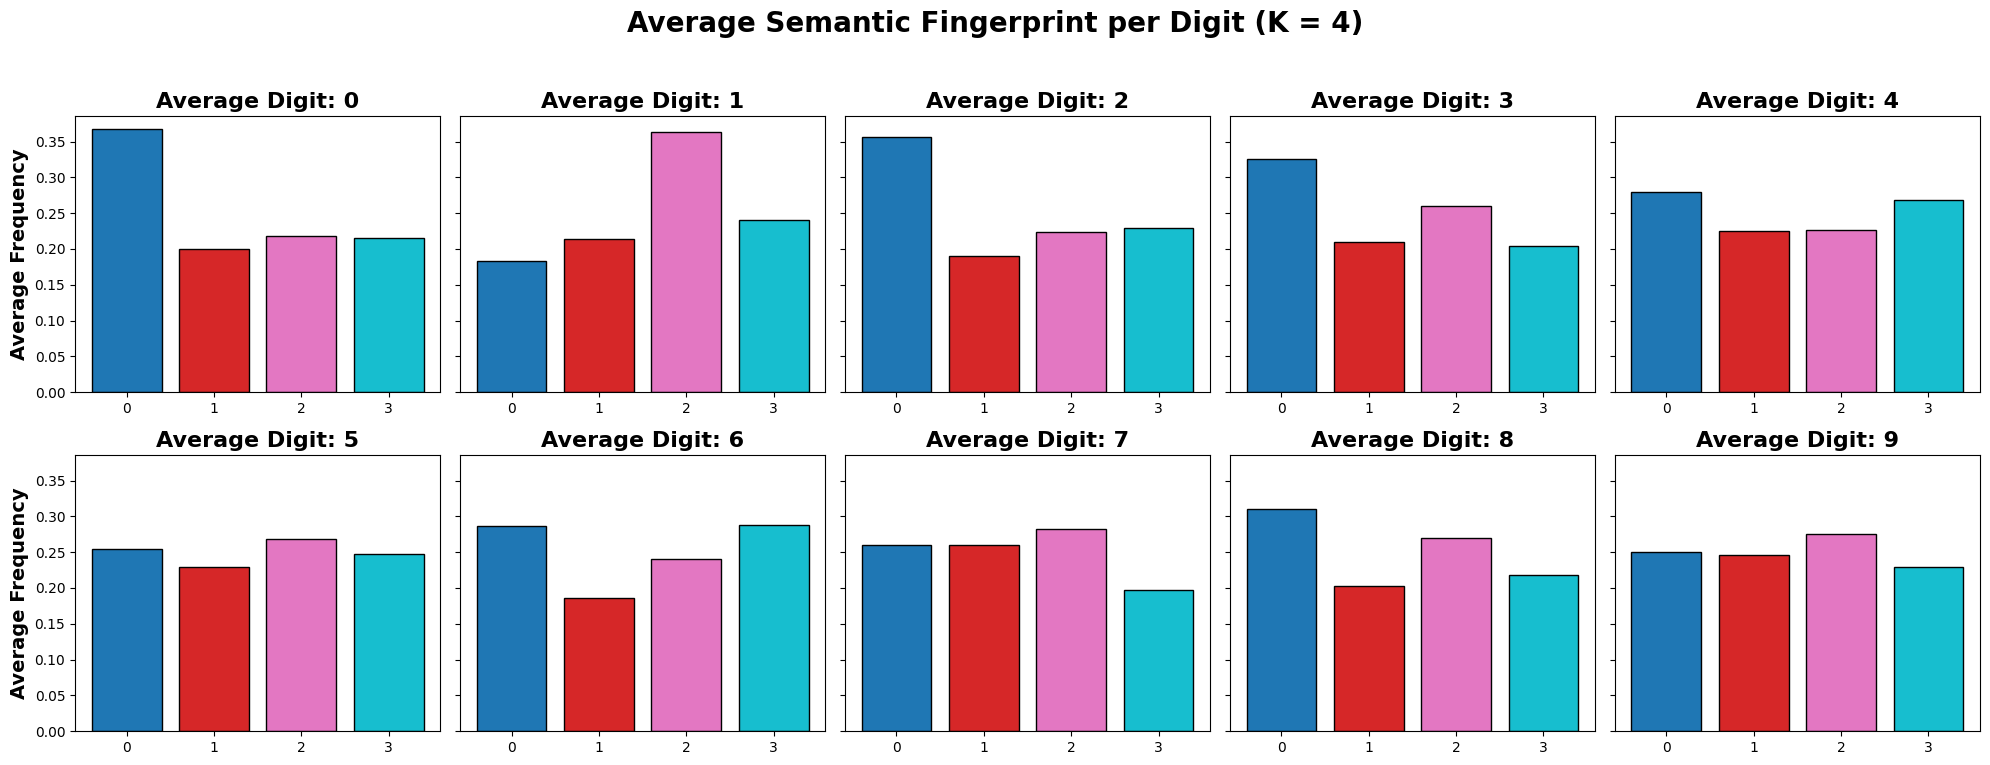

In [49]:
avg_hists_4 = plot_average_histograms(4, train_labels, train_cluster_labels_dict)

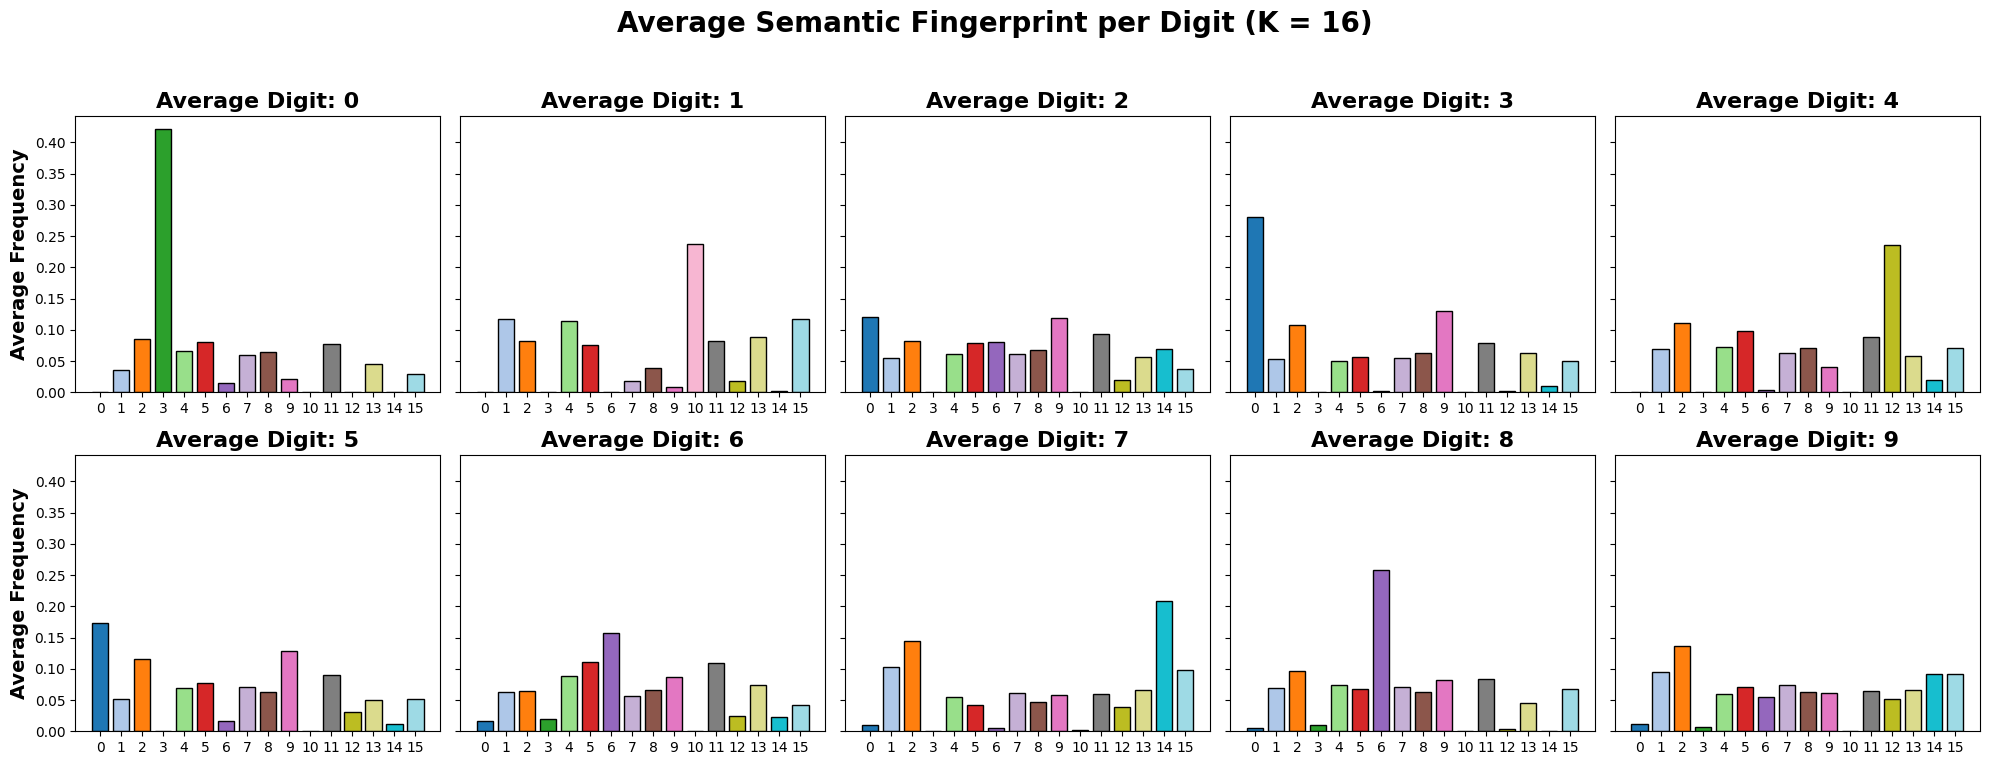

In [93]:
avg_hists_16 = plot_average_histograms(16, train_labels, train_cluster_labels_dict)

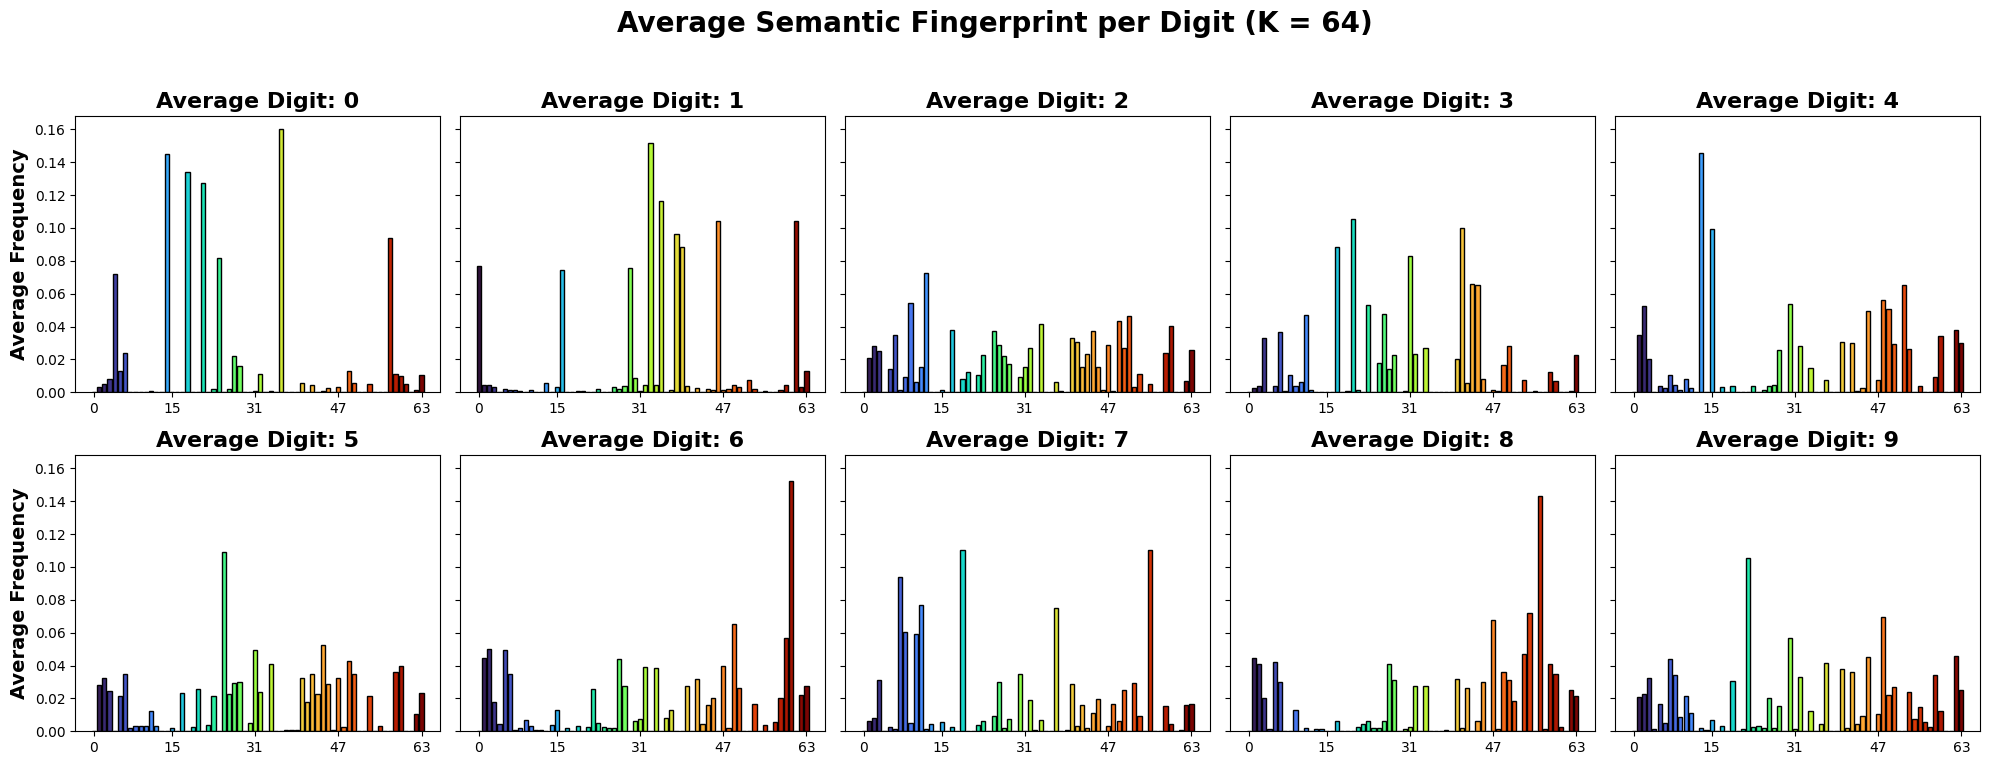

In [94]:
avg_hists_64 = plot_average_histograms(64, train_labels, train_cluster_labels_dict)

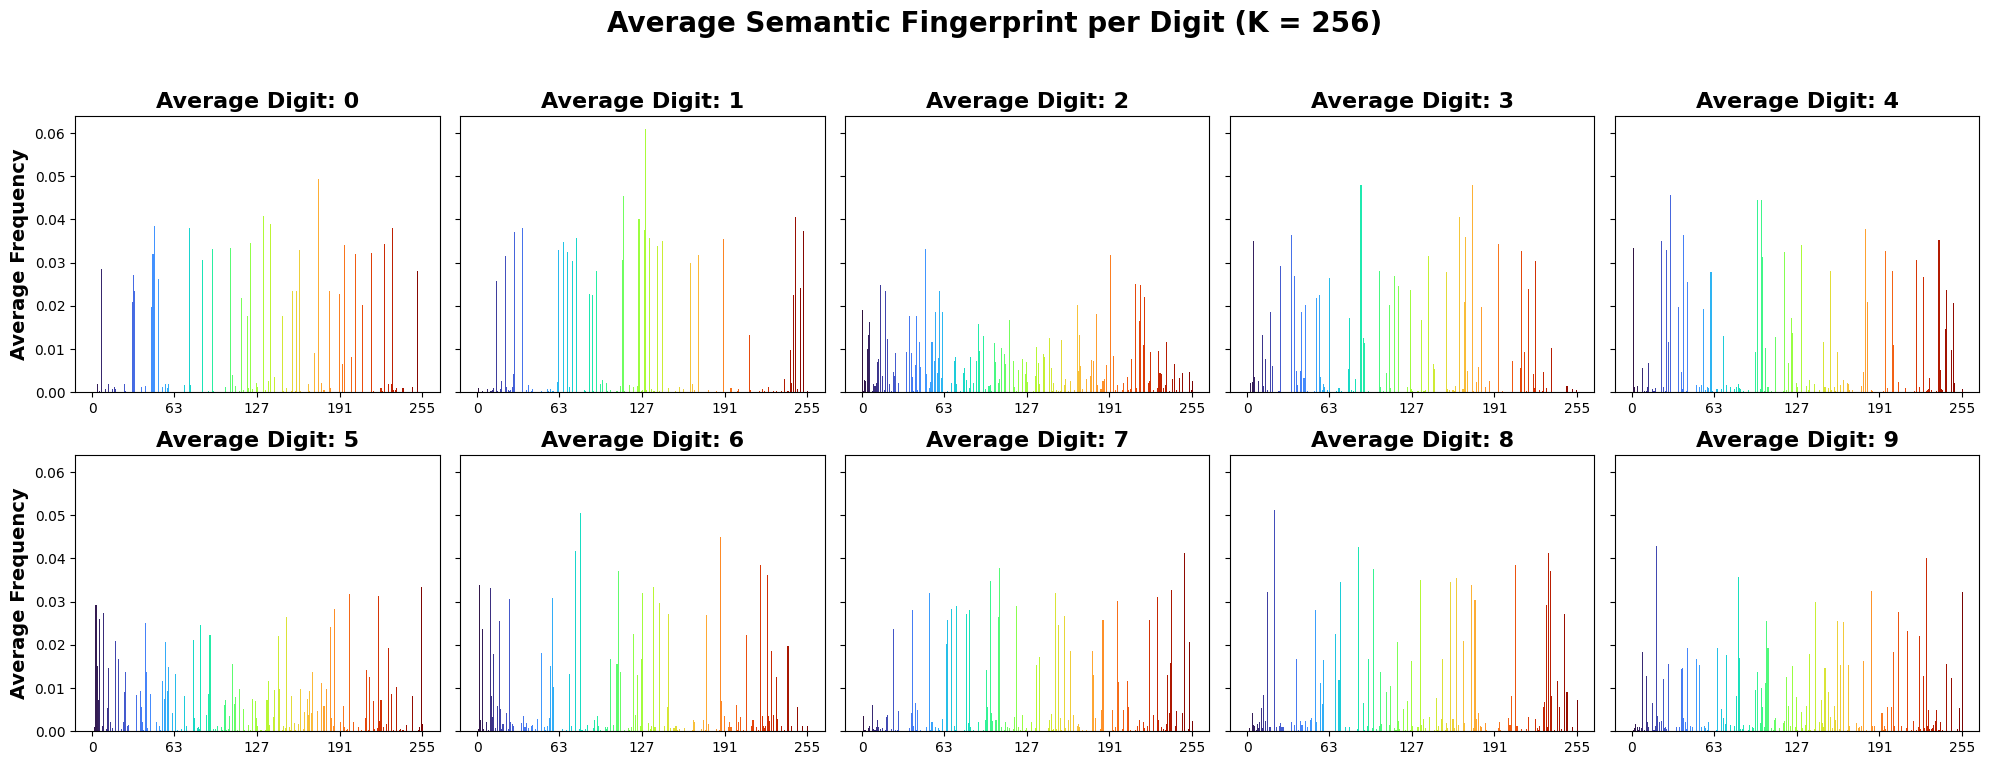

In [95]:
avg_hists_256 = plot_average_histograms(256, train_labels, train_cluster_labels_dict)

## **3. Test Data Preparation**

### **3.1 Feature Extraction**

In [116]:
test_features_list = []

In [117]:
# Extract features for the 100 test images (just like we did for train)
model.eval()
with torch.no_grad():
    for i, img in enumerate(test_images):
        inputs = processor(images=img, return_tensors="pt").to(device)
        inputs['pixel_values'] = inputs['pixel_values'].to(torch.float32)
        outputs = model(**inputs)

        # 14x14 grid = 196 patches
        patch_tokens = outputs.last_hidden_state[0, -196:, :].cpu().numpy()
        test_features_list.append(patch_tokens)

print("✅ Test features extracted!\n")

✅ Test features extracted!



### **3.2 Histogram Generation Function**

In [118]:
def generate_histograms(features_list, kmeans_model, vocab_size):
    """Assigns patches to clusters and builds normalized frequency histograms."""
    histograms = []
    for patches in features_list:
        # Predict which cluster each of the 196 patches belongs to
        labels = kmeans_model.predict(patches)
        # Count them up and divide by 196 to get percentages -> L1 Normalization
        counts = np.bincount(labels, minlength=vocab_size)
        histograms.append(counts / len(labels))
    return np.array(histograms)

### **3.3 Chi-Square calculation**

In [99]:
def chi_square_distance(hist_A, hist_B, eps=1e-10):
    return 0.5 * np.sum(((hist_A - hist_B) ** 2) / (hist_A + hist_B + eps))

## **4. K-NN Classification with 4 Clusters**

### **4.1 Function Definitions**

In [119]:
from collections import Counter

In [120]:
TEST_NEIGHBORS = 1
TEST_NEIGHBORS_3 = 3
TEST_NEIGHBORS_5 = 5
TEST_NEIGHBORS_7 = 7

In [102]:
def run_knn_experiment(vocab_k, n_neighbors, train_feats, test_feats, train_lbls, test_lbls, kmeans_dict):
    """
    Runs a single K-NN classification experiment and returns the accuracy and predictions.
    """
    print(f"⚙️ Running Experiment: Vocab Clusters (K) = {vocab_k} | K-NN Neighbors = {n_neighbors}")

    kmeans_model = kmeans_dict[vocab_k]

    train_hists = generate_histograms(train_feats, kmeans_model, vocab_k)
    test_hists = generate_histograms(test_feats, kmeans_model, vocab_k)

    test_predictions = []
    correct = 0

    for test_idx, test_hist in enumerate(test_hists):
        distances = []
        for train_hist in train_hists:
            distances.append(chi_square_distance(test_hist, train_hist))

        nearest_indices = np.argsort(distances)[:n_neighbors]
        nearest_labels = [train_lbls[idx] for idx in nearest_indices]

        # Majority vote
        pred_label = Counter(nearest_labels).most_common(1)[0][0]
        test_predictions.append(pred_label)

        if pred_label == test_lbls[test_idx]:
            correct += 1

    accuracy = (correct / len(test_lbls)) * 100
    return accuracy, np.array(test_predictions)

In [103]:
def plot_misclassified_images(vocab_k, predictions, test_imgs, test_lbls, test_feats, kmeans_dict, max_plots=5):
    """
    Finds incorrectly classified images, predicts their cluster map,
    and plots the original image alongside the semantic overlay.
    """
    # Find all indices where the prediction was wrong
    wrong_indices = np.where(predictions != test_lbls)[0]

    if len(wrong_indices) == 0:
        print(f"🎉 100% Accuracy! There are no misclassified images to plot for K={vocab_k}.")
        return

    print(f"🔍 Found {len(wrong_indices)} misclassified images. Plotting up to {max_plots}...")

    # Limit how many we plot so we don't crash the notebook
    plot_count = min(len(wrong_indices), max_plots)
    wrong_indices_to_plot = wrong_indices[:plot_count]

    # Colormap logic
    if vocab_k <= 10: cmap_name = 'tab10'
    elif vocab_k <= 20: cmap_name = 'tab20'
    else: cmap_name = 'turbo'
    discrete_cmap = plt.get_cmap(cmap_name, vocab_k)

    fig, axes = plt.subplots(2, plot_count, figsize=(4 * plot_count, 8))

    # If there's only 1 wrong image, axes is 1D. Let's force it to 2D for consistency.
    if plot_count == 1:
        axes = axes.reshape(2, 1)

    kmeans_model = kmeans_dict[vocab_k]

    for i, test_idx in enumerate(wrong_indices_to_plot):
        img = test_imgs[test_idx]
        true_lbl = test_lbls[test_idx]
        pred_lbl = predictions[test_idx]

        # Extract features and predict cluster grid
        patches = test_feats[test_idx]
        labels_1d = kmeans_model.predict(patches)
        cluster_grid_2d = labels_1d.reshape((14, 14))

        # Plot Original (Row 0)
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"True: {true_lbl} | Pred: {pred_lbl}", fontsize=16, fontweight='bold', color='red')
        axes[0, i].axis('off')

        # Plot Overlay (Row 1)
        axes[1, i].imshow(img)
        axes[1, i].imshow(
            cluster_grid_2d, cmap=discrete_cmap, alpha=0.6,
            extent=[0, 224, 224, 0], interpolation='nearest',
            vmin=-0.5, vmax=vocab_k - 0.5
        )
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

### **5. Evaluation**

In [121]:
vocab_sizes = [4, 16, 64, 256]
knn_neighbors = [1, 3, 5, 7]


🚀 TESTING VOCABULARY SIZE (CLUSTERS) K = 4

--- Testing 1-NN with 4 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 4 | K-NN Neighbors = 1
🎯 Final Accuracy (1-NN, K=4): 38.4%

🔍 Found 308 misclassified images. Plotting up to 3...


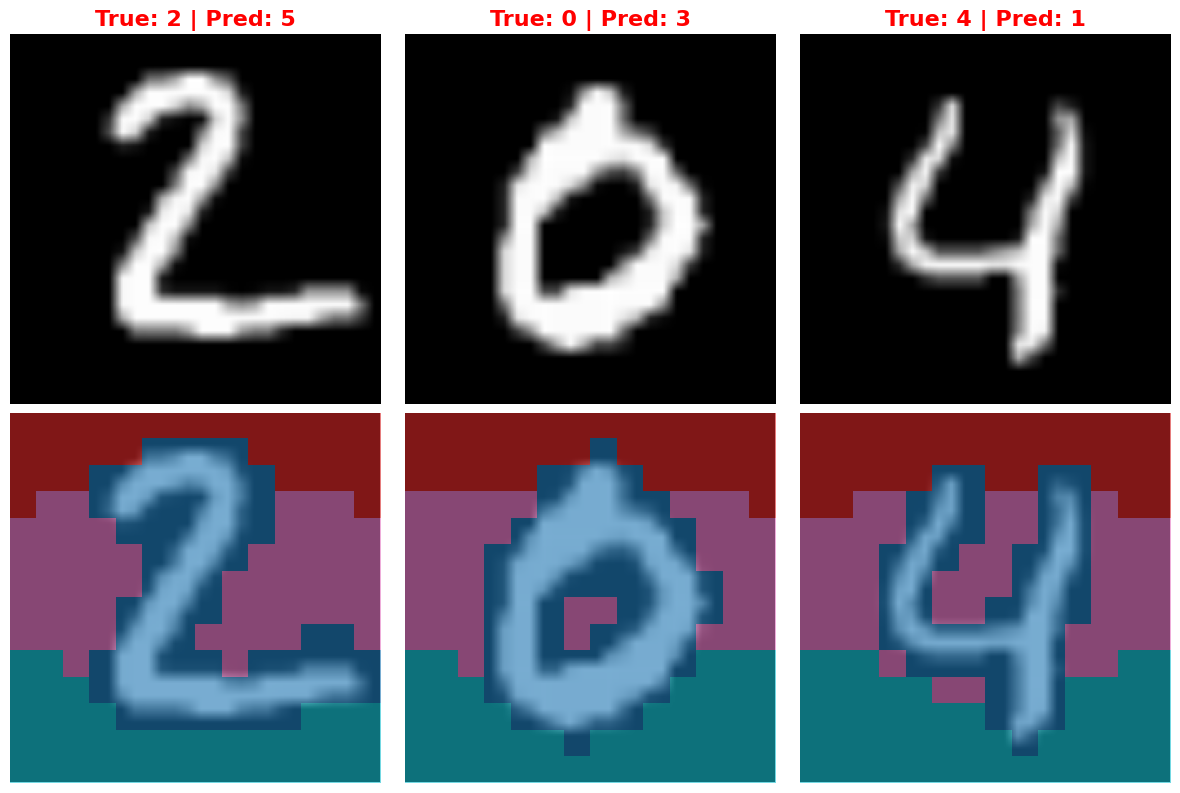


--- Testing 3-NN with 4 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 4 | K-NN Neighbors = 3
🎯 Final Accuracy (3-NN, K=4): 42.4%

🔍 Found 288 misclassified images. Plotting up to 3...


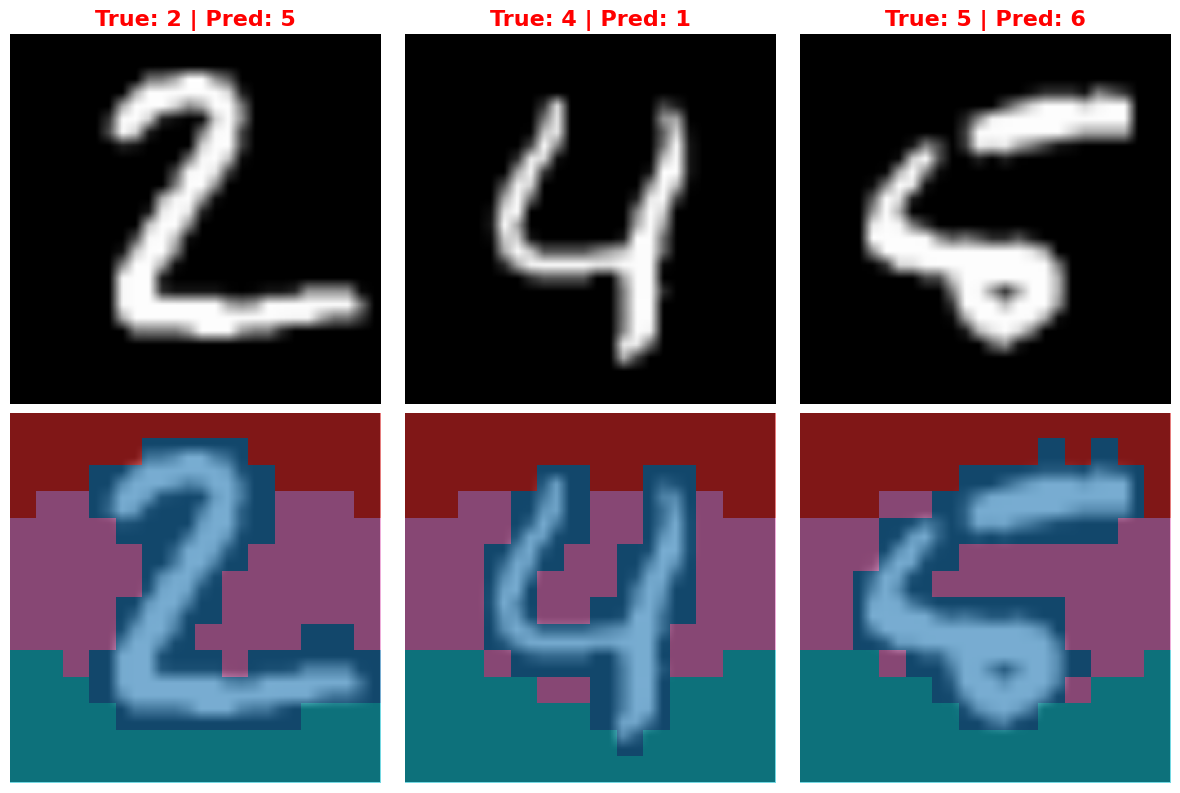


--- Testing 5-NN with 4 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 4 | K-NN Neighbors = 5
🎯 Final Accuracy (5-NN, K=4): 44.0%

🔍 Found 280 misclassified images. Plotting up to 3...


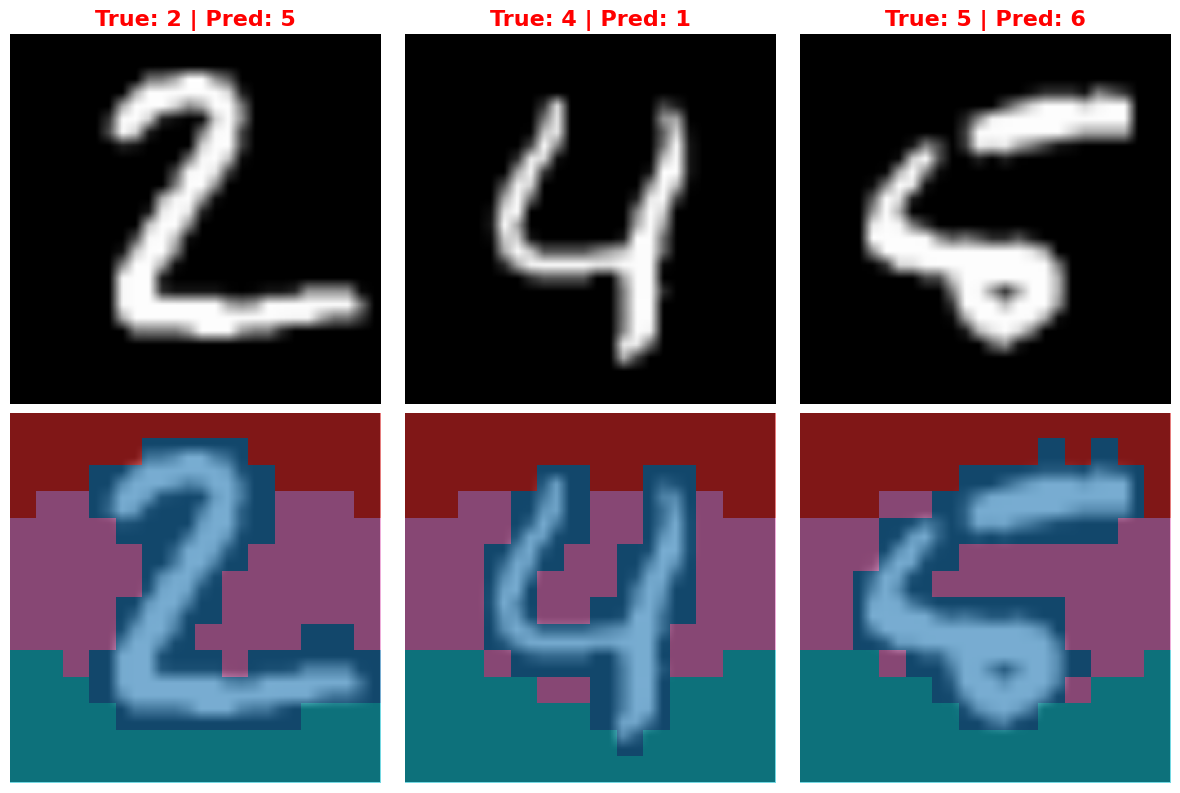


--- Testing 7-NN with 4 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 4 | K-NN Neighbors = 7
🎯 Final Accuracy (7-NN, K=4): 46.2%

🔍 Found 269 misclassified images. Plotting up to 3...


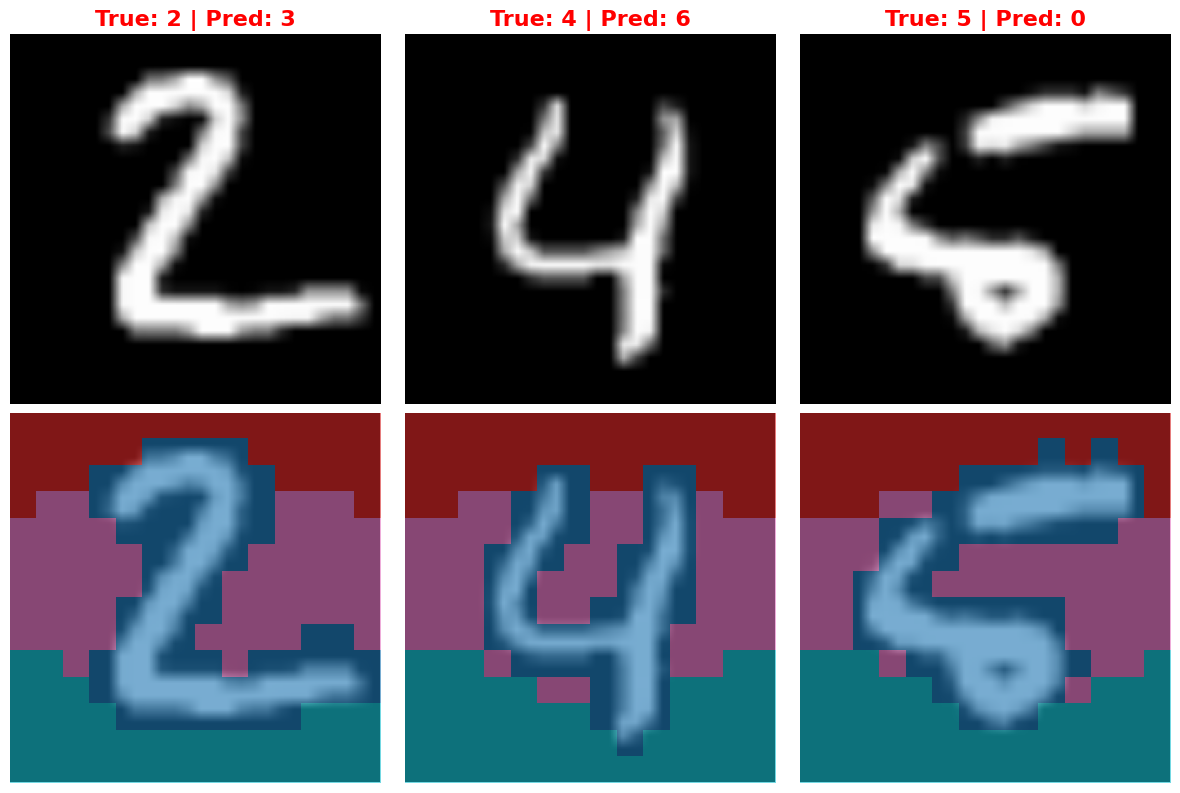


🚀 TESTING VOCABULARY SIZE (CLUSTERS) K = 16

--- Testing 1-NN with 16 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 16 | K-NN Neighbors = 1
🎯 Final Accuracy (1-NN, K=16): 66.2%

🔍 Found 169 misclassified images. Plotting up to 3...


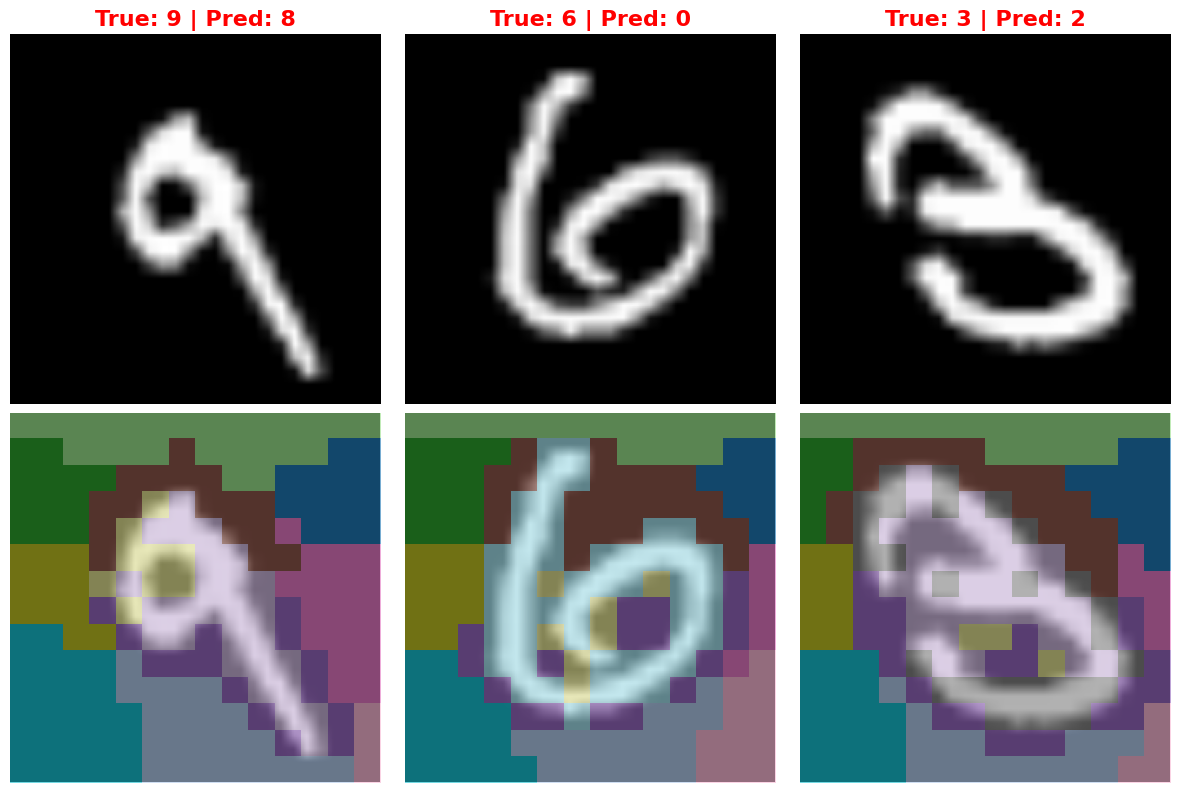


--- Testing 3-NN with 16 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 16 | K-NN Neighbors = 3
🎯 Final Accuracy (3-NN, K=16): 67.0%

🔍 Found 165 misclassified images. Plotting up to 3...


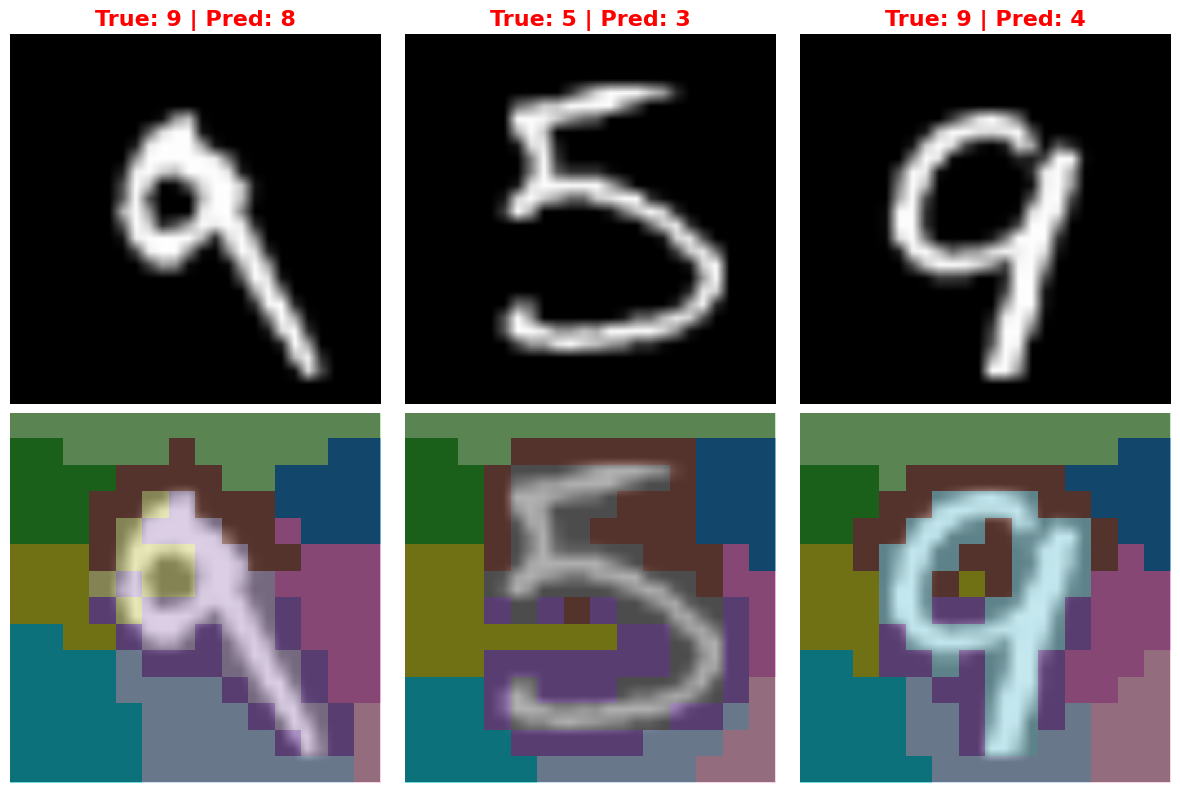


--- Testing 5-NN with 16 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 16 | K-NN Neighbors = 5
🎯 Final Accuracy (5-NN, K=16): 65.8%

🔍 Found 171 misclassified images. Plotting up to 3...


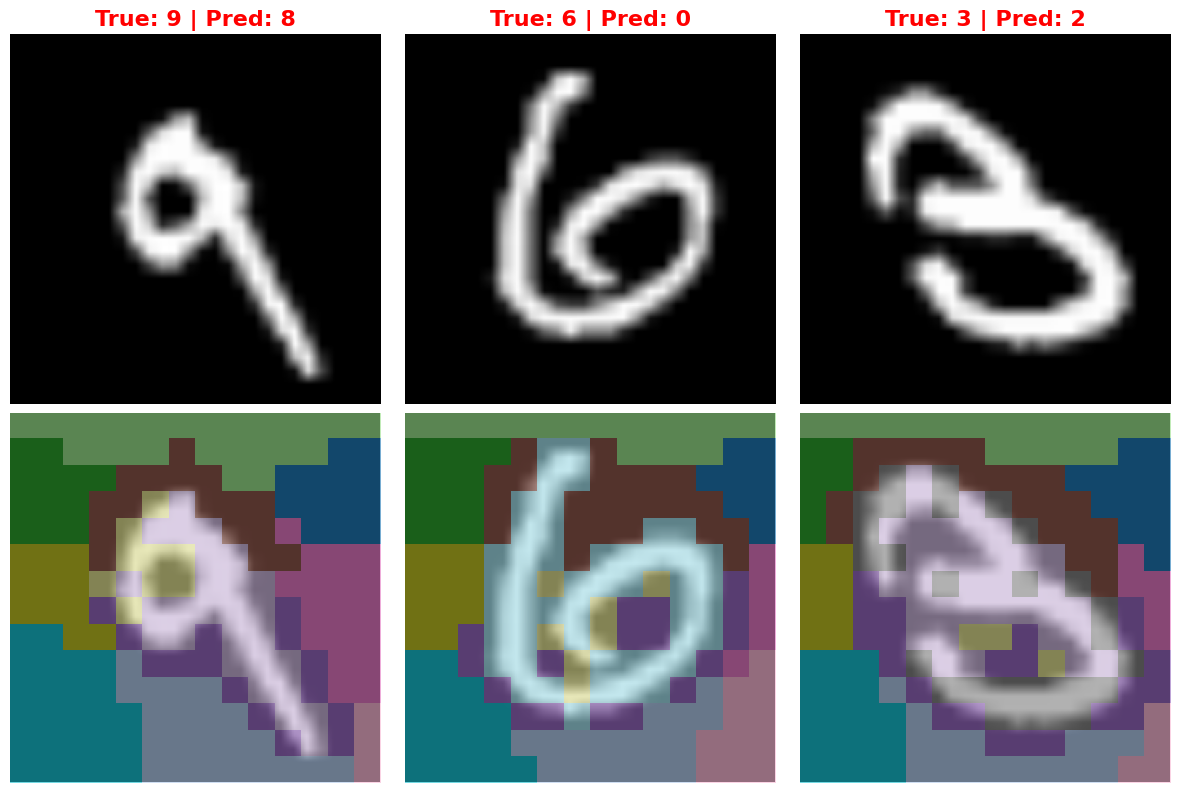


--- Testing 7-NN with 16 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 16 | K-NN Neighbors = 7
🎯 Final Accuracy (7-NN, K=16): 68.8%

🔍 Found 156 misclassified images. Plotting up to 3...


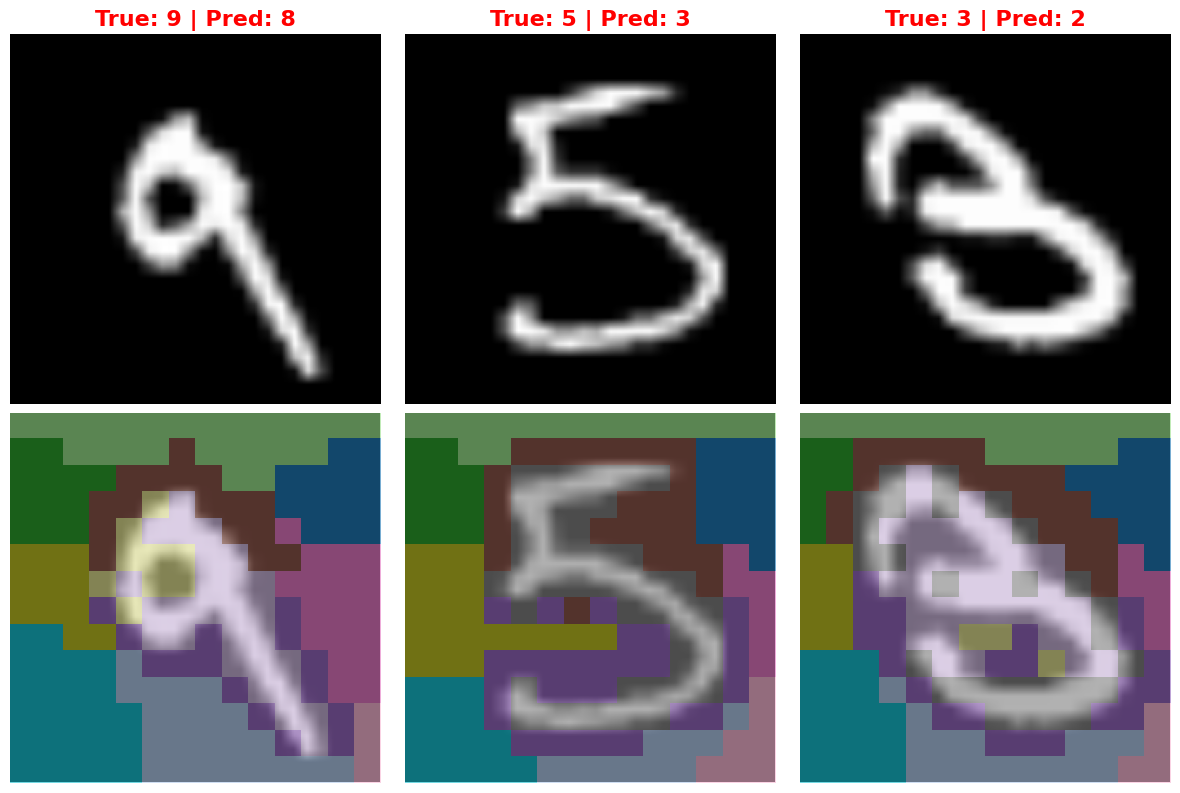


🚀 TESTING VOCABULARY SIZE (CLUSTERS) K = 64

--- Testing 1-NN with 64 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 64 | K-NN Neighbors = 1
🎯 Final Accuracy (1-NN, K=64): 76.2%

🔍 Found 119 misclassified images. Plotting up to 3...


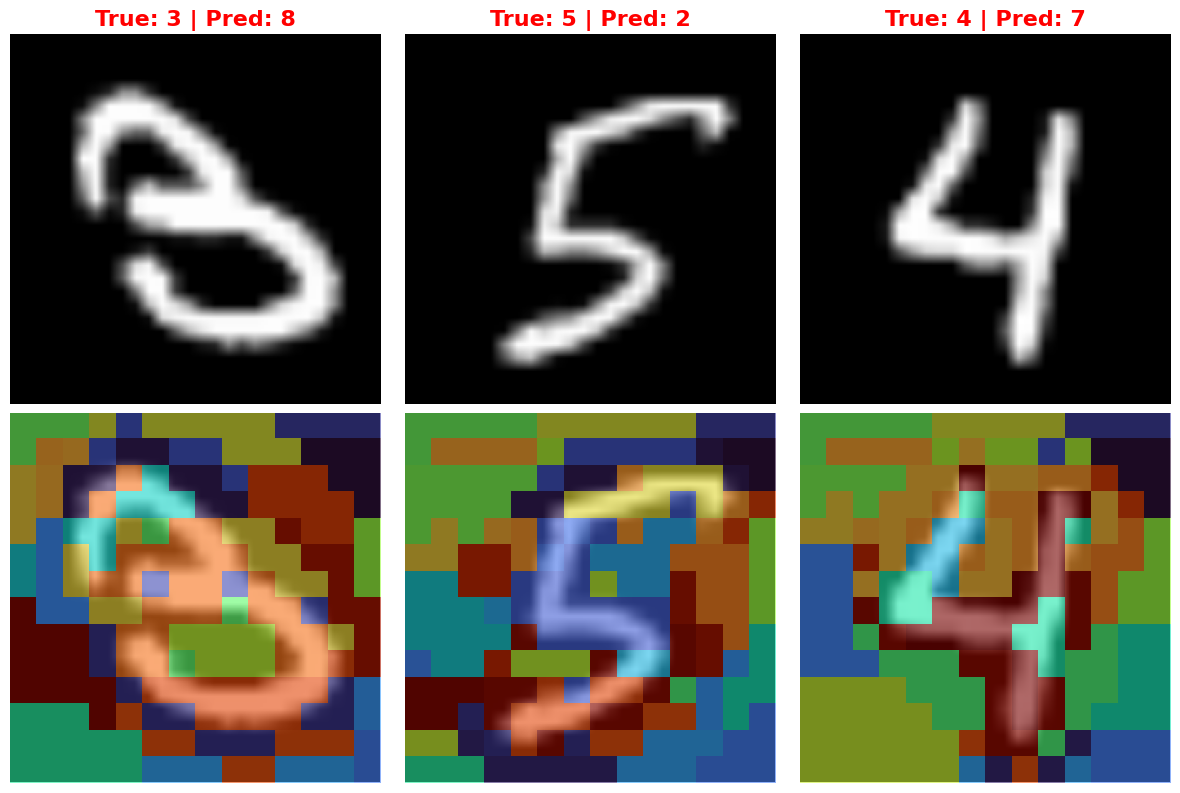


--- Testing 3-NN with 64 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 64 | K-NN Neighbors = 3
🎯 Final Accuracy (3-NN, K=64): 77.0%

🔍 Found 115 misclassified images. Plotting up to 3...


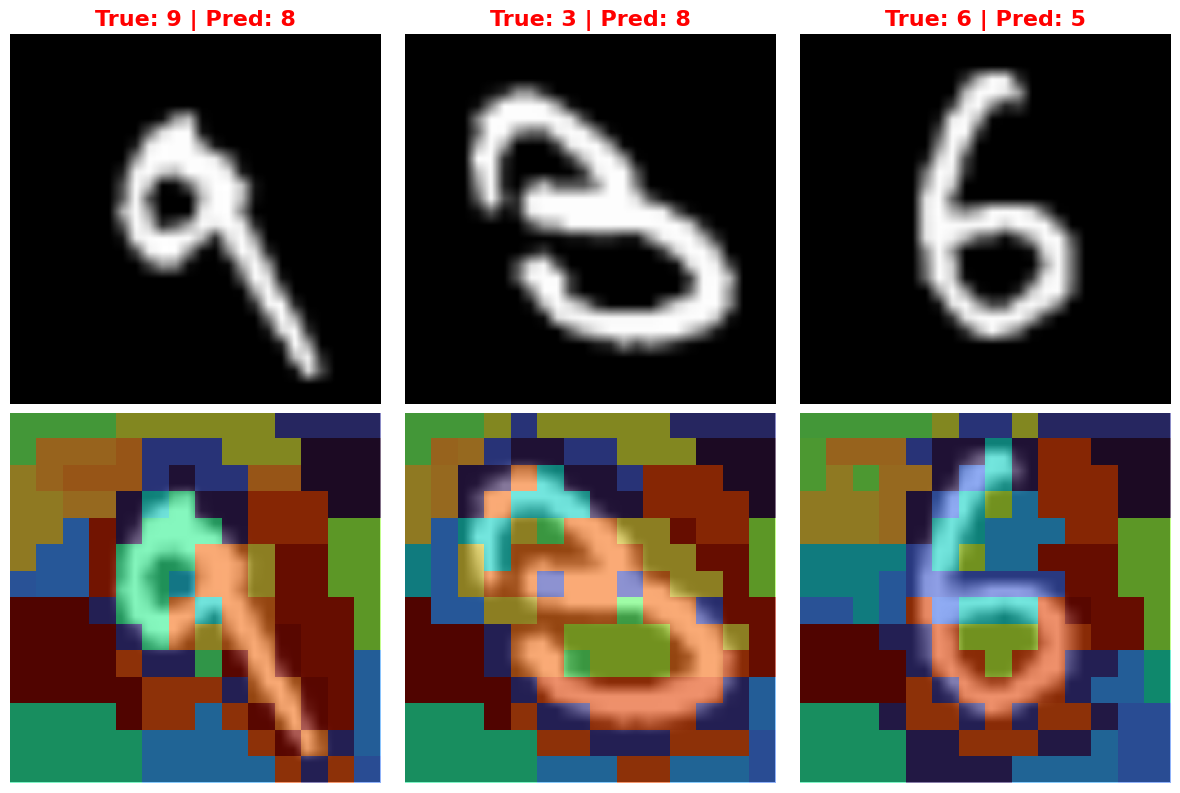


--- Testing 5-NN with 64 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 64 | K-NN Neighbors = 5
🎯 Final Accuracy (5-NN, K=64): 76.0%

🔍 Found 120 misclassified images. Plotting up to 3...


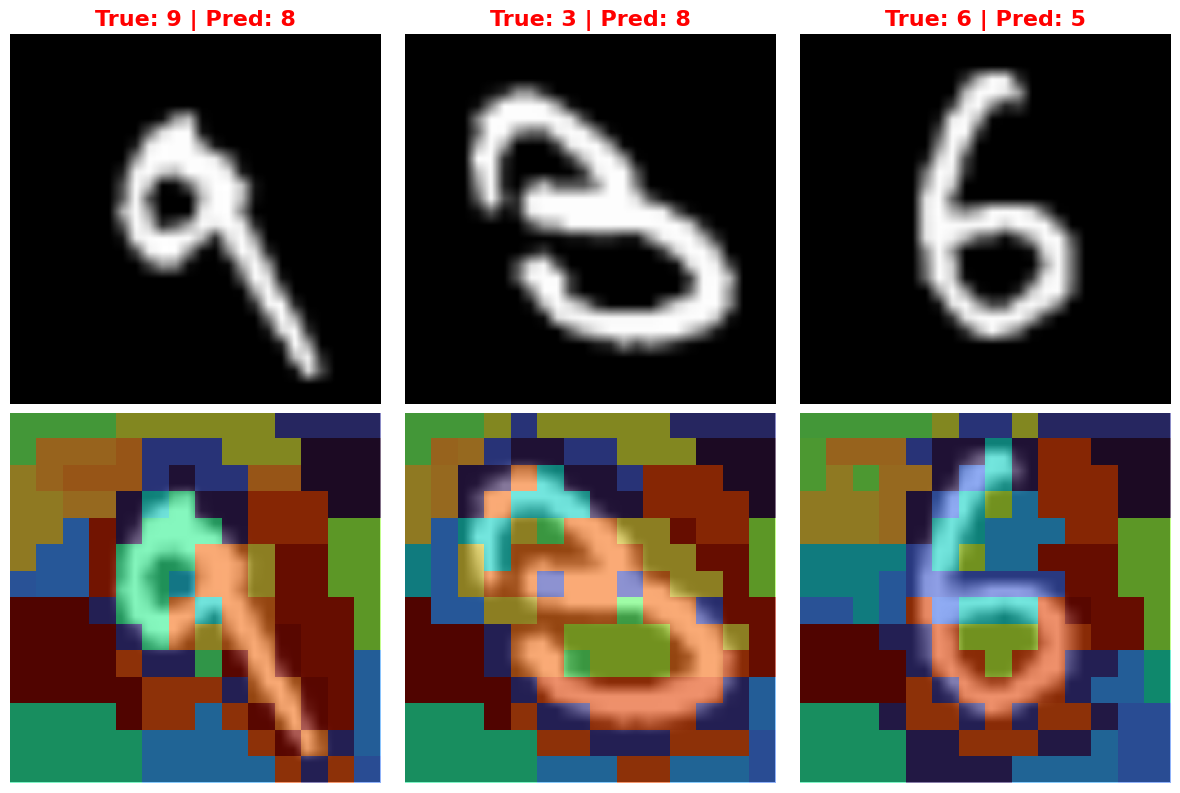


--- Testing 7-NN with 64 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 64 | K-NN Neighbors = 7
🎯 Final Accuracy (7-NN, K=64): 75.8%

🔍 Found 121 misclassified images. Plotting up to 3...


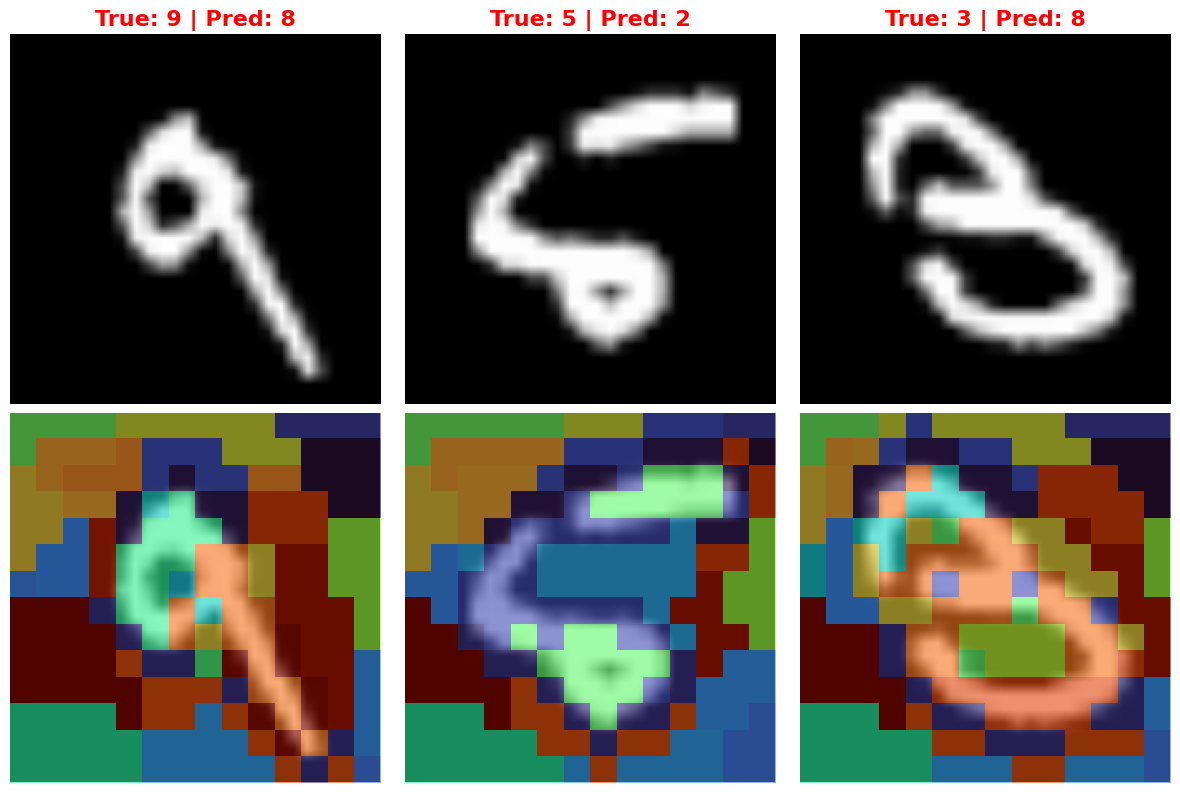


🚀 TESTING VOCABULARY SIZE (CLUSTERS) K = 256

--- Testing 1-NN with 256 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 256 | K-NN Neighbors = 1
🎯 Final Accuracy (1-NN, K=256): 85.6%

🔍 Found 72 misclassified images. Plotting up to 3...


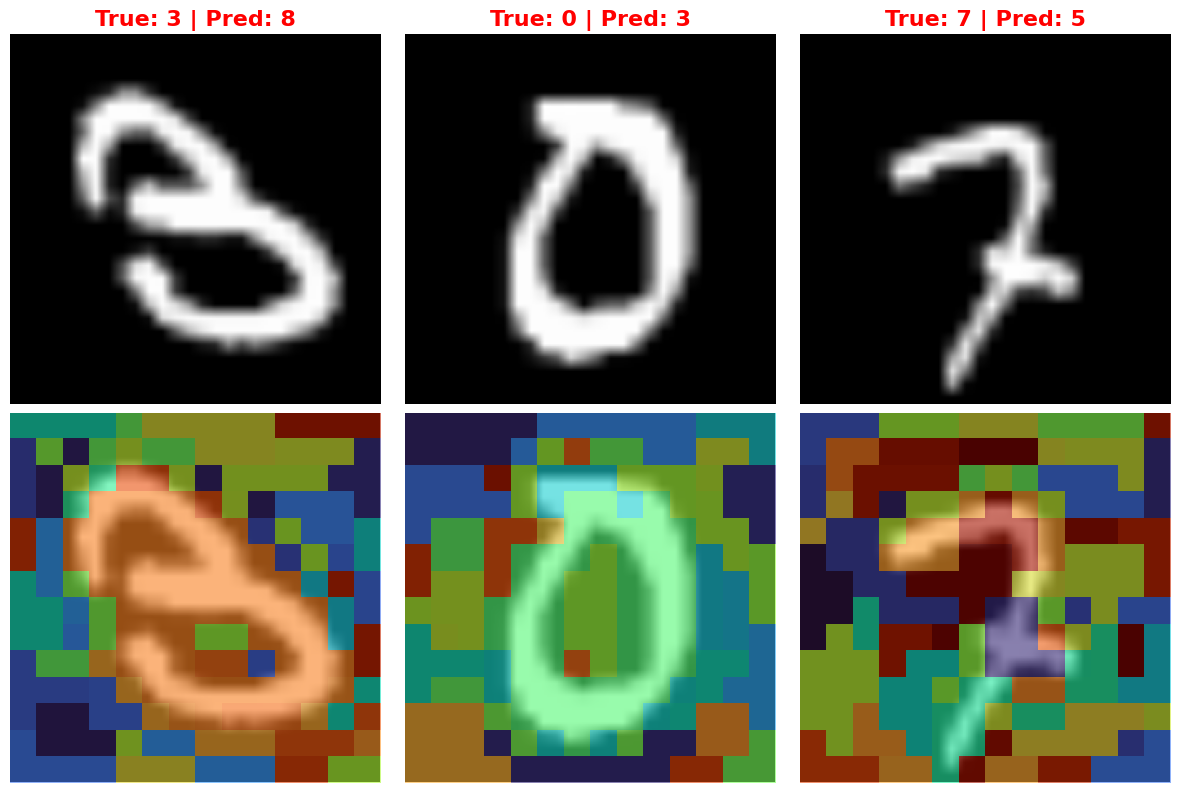


--- Testing 3-NN with 256 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 256 | K-NN Neighbors = 3
🎯 Final Accuracy (3-NN, K=256): 86.0%

🔍 Found 70 misclassified images. Plotting up to 3...


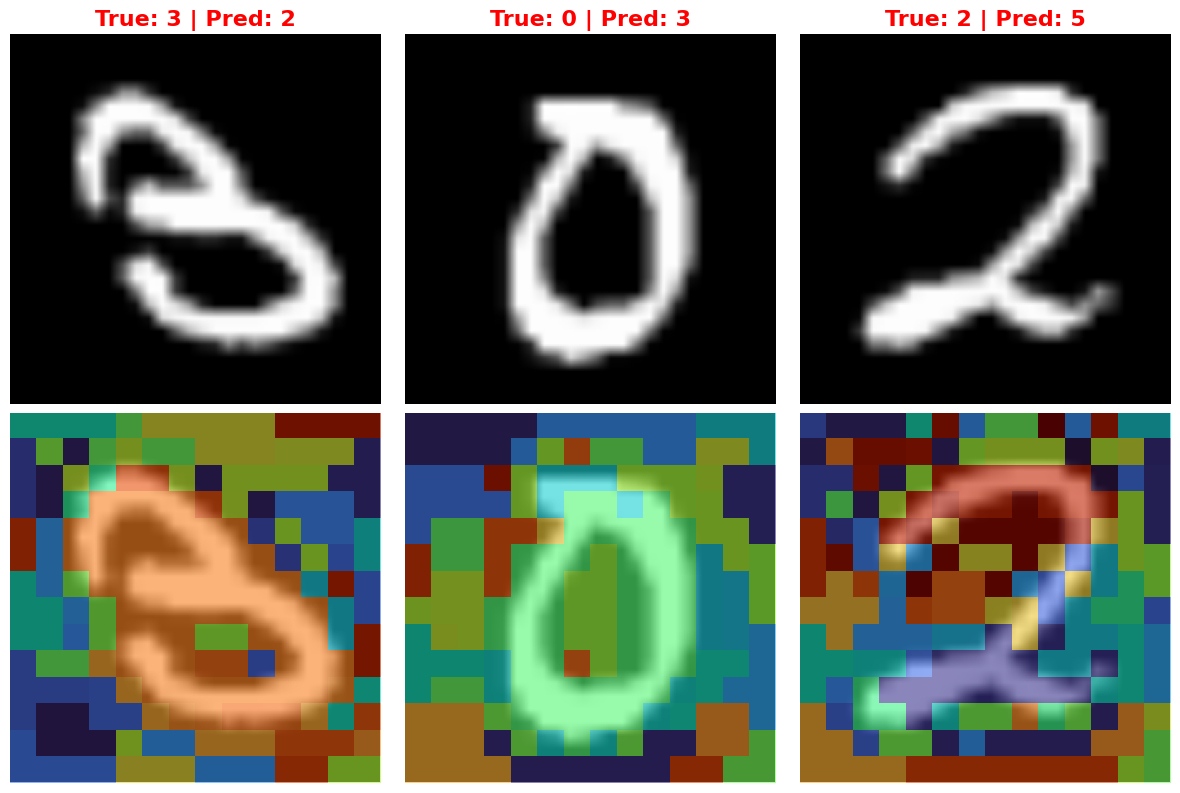


--- Testing 5-NN with 256 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 256 | K-NN Neighbors = 5
🎯 Final Accuracy (5-NN, K=256): 84.4%

🔍 Found 78 misclassified images. Plotting up to 3...


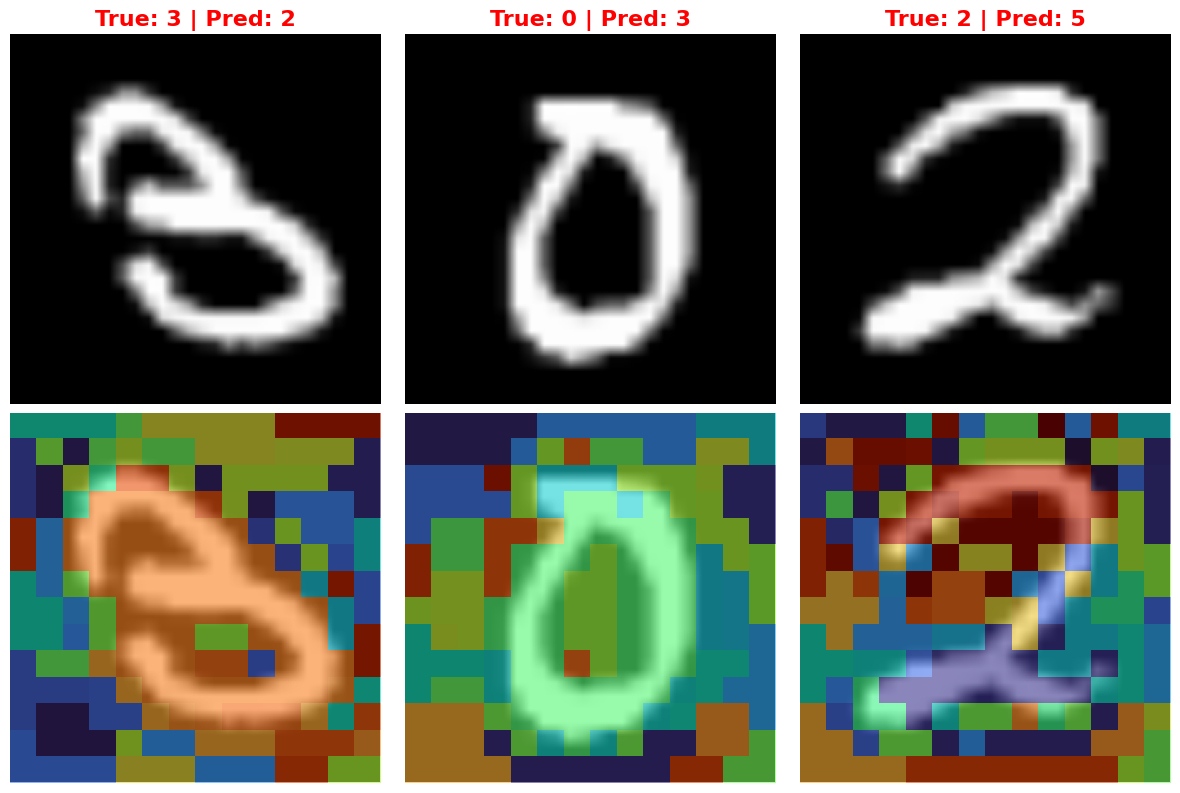


--- Testing 7-NN with 256 Clusters ---
⚙️ Running Experiment: Vocab Clusters (K) = 256 | K-NN Neighbors = 7
🎯 Final Accuracy (7-NN, K=256): 84.4%

🔍 Found 78 misclassified images. Plotting up to 3...


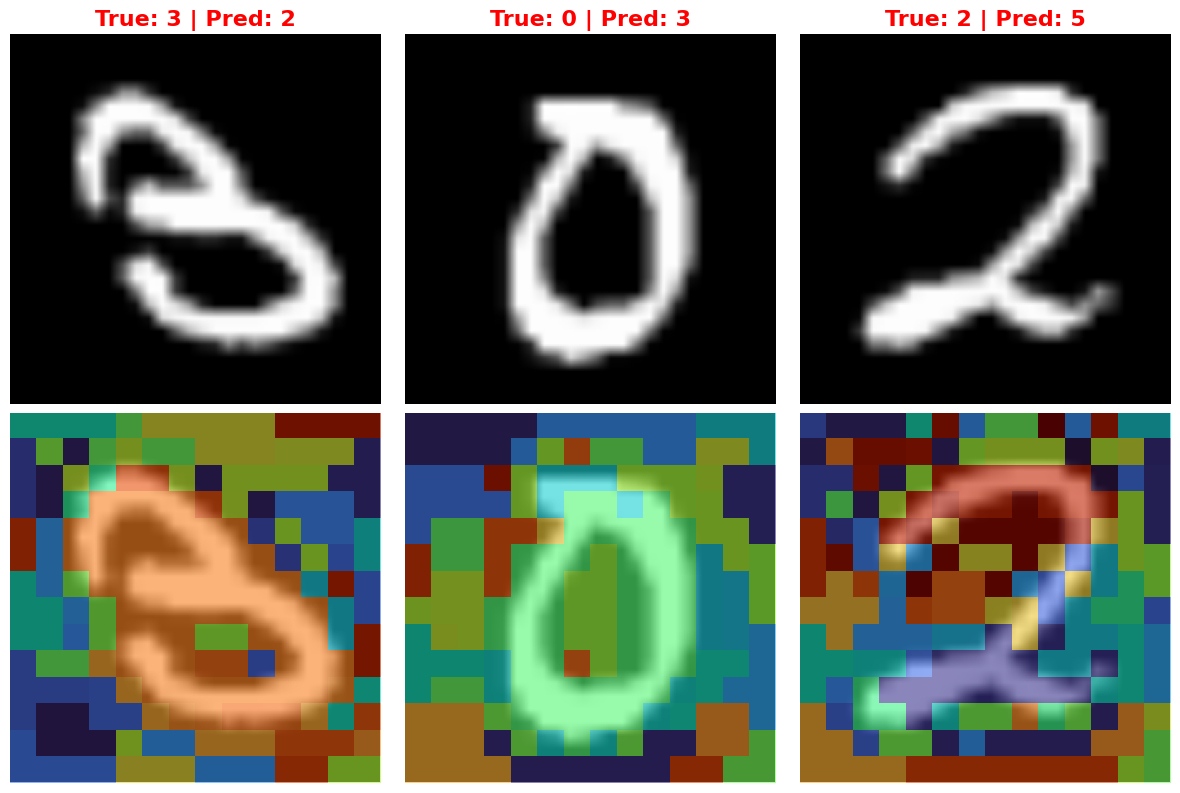

In [122]:
for vocab in vocab_sizes:
    print(f"\n{'='*60}")
    print(f"🚀 TESTING VOCABULARY SIZE (CLUSTERS) K = {vocab}")
    print(f"{'='*60}")

    for nn in knn_neighbors:
        print(f"\n--- Testing {nn}-NN with {vocab} Clusters ---")

        # 1. Run the specific experiment
        acc, preds = run_knn_experiment(
            vocab_k=vocab,
            n_neighbors=nn,
            train_feats=train_features_list,
            test_feats=test_features_list,
            train_lbls=train_labels,
            test_lbls=test_labels,
            kmeans_dict=kmeans_models
        )

        print(f"🎯 Final Accuracy ({nn}-NN, K={vocab}): {acc:.1f}%\n")

        plot_misclassified_images(
            vocab_k=vocab,
            predictions=preds,
            test_imgs=test_images,
            test_lbls=test_labels,
            test_feats=test_features_list,
            kmeans_dict=kmeans_models,
            max_plots=3
        )

### **5.2 Errors**

In [ ]:
experiment_labels = []
error_matrix = []
worst_digits_info = []

# Loop through our grid to gather the exact mistake counts
for vocab in vocab_sizes:
    for nn in knn_neighbors:
        # Run the experiment silently to grab the predictions
        acc, preds = run_knn_experiment(
            vocab_k=vocab,
            n_neighbors=nn,
            train_feats=train_features_list,
            test_feats=test_features_list,
            train_lbls=train_labels,
            test_lbls=test_labels,
            kmeans_dict=kmeans_models
        )

        # Tally up the errors for each specific digit (0 through 9)
        digit_errors = np.zeros(10, dtype=int)
        for true_label, pred_label in zip(test_labels, preds):
            if true_label != pred_label:
                digit_errors[true_label] += 1

        error_matrix.append(digit_errors)
        experiment_labels.append(f"V={vocab} | {nn}-NN")

        # Find the absolute worst digit for this specific setup
        worst_digit = np.argmax(digit_errors)
        max_errors = digit_errors[worst_digit]
        worst_digits_info.append(f"Digit {worst_digit} ({max_errors} errors)")

error_matrix = np.array(error_matrix)

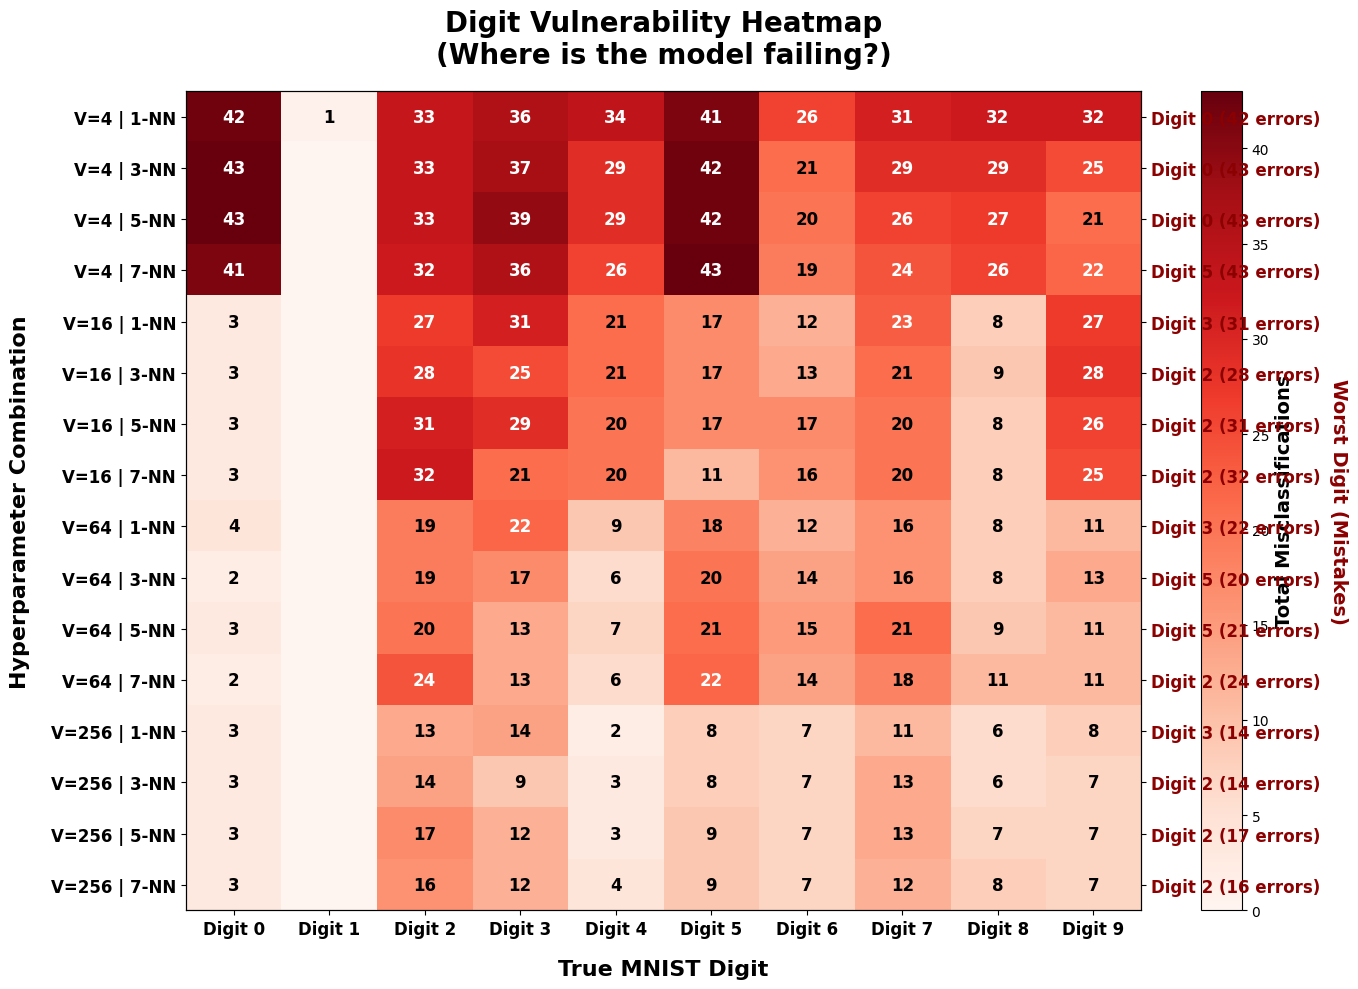

In [124]:
fig, ax = plt.subplots(figsize=(14, 10))

cax = ax.imshow(error_matrix, cmap='Reds', aspect='auto')

cbar = fig.colorbar(cax)
cbar.set_label('Total Misclassifications', fontsize=14, fontweight='bold')

ax.set_xticks(np.arange(10))
ax.set_yticks(np.arange(len(experiment_labels)))
ax.set_xticklabels([f"Digit {i}" for i in range(10)], fontsize=12, fontweight='bold')
ax.set_yticklabels(experiment_labels, fontsize=12, fontweight='bold')
ax.set_xlabel("True MNIST Digit", fontsize=16, fontweight='bold', labelpad=15)
ax.set_ylabel("Hyperparameter Combination", fontsize=16, fontweight='bold', labelpad=15)

for i in range(len(experiment_labels)):
    for j in range(10):

        if error_matrix[i, j] > 0:
            text_color = "white" if error_matrix[i, j] > (np.max(error_matrix) / 2) else "black"
            ax.text(j, i, str(error_matrix[i, j]),
                    ha="center", va="center", color=text_color, fontsize=12, fontweight='bold')

ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(np.arange(len(experiment_labels)))
ax2.set_yticklabels(worst_digits_info, fontsize=12, fontweight='bold', color='darkred')
ax2.set_ylabel("Worst Digit (Mistakes)", fontsize=14, fontweight='bold', color='darkred', rotation=-90, labelpad=20)

plt.title("Digit Vulnerability Heatmap\n(Where is the model failing?)", fontsize=20, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()